# Рекомендательная система поисковых кластеров

Система предлагает товару запросы без прошлых заказов и с небольшим числом просмотров. E5 ищет сходство по смыслу, совместные продажи связывают товары и запросы, адаптер и LightGCN обучаются на истории. Ранжирование объединяет четыре сигнала; проверка характеристик отсеивает противоречия товару. Итог — очередь для ручной проверки.

**Основной эксперимент:** [отложенный период 05–18.09](#holdout-check), полный каталог и пять обучений с разными seed. Средний прирост Recall@10 — **+2,25 п.п.**; доверительный интервал включает ноль, поэтому устойчивое преимущество не подтверждено.

[Выводы](#rezultaty) · [Дополнительное окно](#current-check) · [Учебный пример](#model-demo)

Таблицы и графики сохранены, реальные результаты обезличены. Учебные данные — **синтетические**.

In [1]:
from pathlib import Path
import hashlib
import json
import sys

import numpy as np
import pandas as pd
from IPython.display import Markdown, display

SUMMARY_ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
                     if (p / 'src/recommender.py').is_file()), None)
if SUMMARY_ROOT is None:
    raise RuntimeError('Откройте ноутбук из папки клонированного проекта.')
ROOT = SUMMARY_ROOT
sys.path.insert(0, str(ROOT / 'src'))

from ranking_snapshot import snapshot_metrics
from fresh_snapshot import refresh_source_snapshot

pair_path = ROOT / 'reports/notebook_ranking_pairs.csv'
snapshot_info = json.loads((ROOT / 'reports/notebook_ranking_manifest.json').read_text())
summary_path = ROOT / 'reports/experiment_summary.json'
assert hashlib.sha256(pair_path.read_bytes()).hexdigest() == snapshot_info['pairs_sha256']
assert hashlib.sha256(summary_path.read_bytes()).hexdigest() == snapshot_info['experiment_summary_sha256']
real_pairs = pd.read_csv(pair_path, dtype={'baseline_rank': 'Int64', 'system_rank': 'Int64'})
summary_report = json.loads(summary_path.read_text())
real_test = real_pairs.loc[real_pairs.period.eq('test')].copy()
real_metrics = snapshot_metrics(real_test)
for method, reference in [('baseline', 'e5_co_sales'), ('system', 'all_four')]:
    expected_metrics = summary_report['ablation']['test'][reference]
    for metric_name in ['recall@10', 'precision@10', 'ndcg@10', 'retrieval_recall',
                        'evaluated_skus', 'positive_pairs']:
        assert np.isclose(real_metrics[method][metric_name], expected_metrics[metric_name],
                          rtol=1e-10, atol=1e-12)

print('Подготовка данных и проверка контрольных сумм...', flush=True)
current_source = refresh_source_snapshot(ROOT)
print('Данные и сохранённые метрики проверены. Последняя дата источника:', current_source['last_day'])

Подготовка данных и проверка контрольных сумм...
Данные и сохранённые метрики проверены. Последняя дата источника: 2026-10-17


<a id="holdout-check"></a>

## Основной эксперимент: отложенный период

**05–18.09.2026** используются только для подсчёта качества. Адаптер и LightGCN обучаются с нуля; тестовые и более поздние строки недоступны обучению и выбору настроек.

| Данные | Назначение |
|---|---|
| До 07.08 | Обучение весов моделей |
| 08–21.08 | Выбор лучшей эпохи и ранняя остановка |
| 22.08–04.09 | Случайный поиск настроек (`random search`), по три обучения каждого варианта |
| 05–18.09 | Оценка пяти заранее заданных запусков |

Каталог — **477 579 кластеров** словаря от 26.06; E5 заморожена. Четыре канала имеют веса по 0,25, два канала базы — по 0,5. Веса на тесте не подбираются.

**Recall@10** — доля будущих продающих запросов в первых десяти рекомендациях, усреднённая по товарам. Общий пул объединяет кандидатов пяти запусков: сравнивается ранжирование, ненайденные цели учитываются. Усредняются метрики запусков, не их выдачи. 95%-й интервал разницы рассчитывается парной перевыборкой товаров; разброс обучений показан отдельно.

Это **ретроспективная отложенная проверка**: временное разделение уже собранных данных, а не слепой эксперимент на впервые полученных данных.

Переобучение и отложенная проверка воспроизведены; проверены данные, код, веса и выдачи.


,Последний доступный день
Этап,
Обучение весов,2026-08-07
Выбор эпохи,2026-08-21
Выбор архитектуры и построение выдачи,2026-09-04
Подсчёт метрик,2026-09-05 — 2026-09-18


Кластеров: 477579 | пар в общем пуле: 249293


**Отложенный период 2026-09-05 — 2026-09-18:** Recall@10 базы **21.83%**, среднее полной модели **24.08%**. Разница **+2.25 п.п.**, 95%-й интервал **[-1.21; +5.27] п.п.** Разброс между обучениями — **1.42 п.п.**; выше базы **5 из 5** запусков.

,"База, %","Модель, %","Разница, п.п."
seed,,,
7,21.83,24.17,2.34
17,21.83,23.75,1.92
27,21.83,21.88,0.06
37,21.83,25.02,3.20
47,21.83,25.57,3.74


...

Против четырёх каналов без обучения: +5.56 п.п.; 95% интервал [+0.75; +10.36] п.п.


,Товаров,Целей,"База, %","Модель, %","Разница, п.п.","95% интервал, п.п."
История продаж,,,,,,
0 кластеров,0,0,NaN,NaN,NaN,Нет целей
1–5 кластеров,9,17,22.22,31.11,8.89,[+0.00; +22.22]
6–20 кластеров,31,50,38.17,36.38,-1.79,[-10.32; +5.96]
21+ кластеров,64,161,13.85,17.13,3.27,[+0.70; +6.81]


Группы со средним проигрышем базе: 6–20 кластеров


**Вывод:** 95%-й интервал включает ноль: уверенный выигрыш над базой не установлен.

,Модель,Параметры,Среднее NDCG,Разброс NDCG,Выбрано
0,adapter,"{'batch_size': 128, 'hidden_dim': 64}",0.052412,0.004550,True
1,adapter,"{'batch_size': 64, 'hidden_dim': 128}",0.059984,0.011130,False
2,adapter,"{'batch_size': 64, 'hidden_dim': 64}",0.057832,0.006922,False
3,graph,"{'dimensions': 16, 'layers': 1}",0.078543,0.032033,True
4,graph,"{'dimensions': 32, 'layers': 2}",0.096503,0.015517,False
5,graph,"{'dimensions': 64, 'layers': 1}",0.098274,0.013186,False


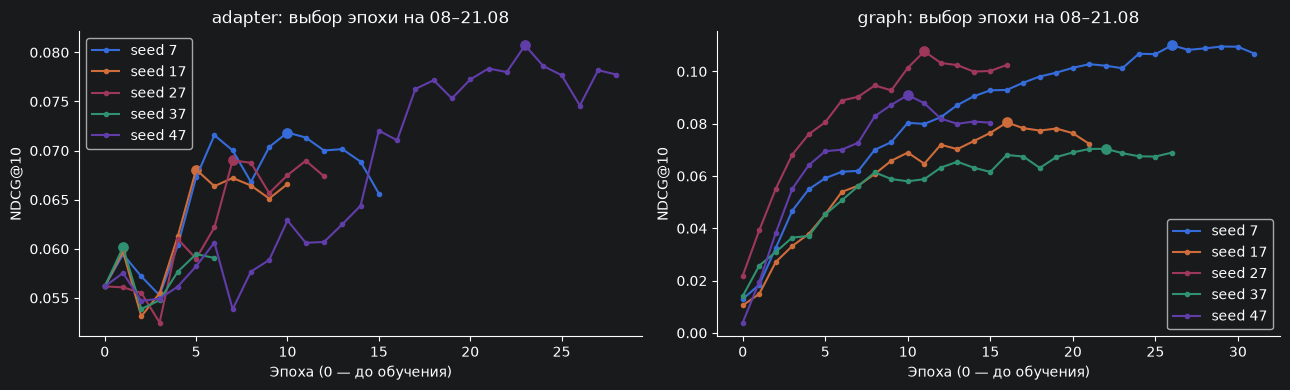

Результаты: reports/notebook_retrospective_holdout.json


In [2]:
from retrospective_holdout import run_retrospective_holdout
import matplotlib.pyplot as plt

heldout_report = run_retrospective_holdout(SUMMARY_ROOT, current_source)
heldout_interval = heldout_report['interval']
heldout_repeat = heldout_report['seed_summary']
assert heldout_report['test_excluded_from_training']
assert not heldout_report['old_trained_weights_used']
assert heldout_report['target_days'] == 14
assert heldout_report['split_audit']['overlapping_dates'] == 0

display(pd.DataFrame([
    {'Этап': 'Обучение весов', 'Последний доступный день': heldout_report['train_end']},
    {'Этап': 'Выбор эпохи', 'Последний доступный день': heldout_report['epoch_validation_end']},
    {'Этап': 'Выбор архитектуры и построение выдачи', 'Последний доступный день': heldout_report['decision']},
    {'Этап': 'Подсчёт метрик', 'Последний доступный день': heldout_report['target_start'] + ' — ' + heldout_report['target_end']},
]).set_index('Этап'))
print('Кластеров:', heldout_report['catalog_clusters'], '| пар в общем пуле:', heldout_report['candidate_pairs'])
if heldout_interval['n_targets']:
    display(Markdown(f"**Отложенный период {heldout_report['target_start']} — {heldout_report['target_end']}:** "
        f"Recall@10 базы **{100 * heldout_interval['baseline']:.2f}%**, среднее полной модели **{100 * heldout_interval['system']:.2f}%**. "
        f"Разница **{100 * heldout_interval['difference']:+.2f} п.п.**, 95%-й интервал "
        f"**[{100 * heldout_interval['lower']:+.2f}; {100 * heldout_interval['upper']:+.2f}] п.п.** "
        f"Разброс между обучениями — **{100 * heldout_repeat['std_gain']:.2f} п.п.**; "
        f"выше базы **{heldout_repeat['wins']} из {heldout_repeat['count']}** запусков."))
    heldout_seeds = pd.DataFrame(heldout_report['seeds']).set_index('seed')
    display((100 * heldout_seeds).rename(columns={
        'baseline': 'База, %', 'system': 'Модель, %', 'difference': 'Разница, п.п.'}).round(2))
    heldout_ablation = pd.DataFrame([{
        'Вариант': name, 'Recall@10, %': 100 * metrics['recall@10'], 'NDCG@10': metrics['ndcg@10']
    } for name, metrics in heldout_report['ablation'].items()])
    display(heldout_ablation.set_index('Вариант').round(4))
    heldout_channels = heldout_report['channel_count_interval']
    print(f"Против четырёх каналов без обучения: {100 * heldout_channels['difference']:+.2f} п.п.; "
          f"95% интервал [{100 * heldout_channels['lower']:+.2f}; {100 * heldout_channels['upper']:+.2f}] п.п.")
    heldout_slices = pd.DataFrame([{
        'История продаж': row['history'], 'Товаров': row['n_skus'], 'Целей': row['n_targets'],
        'База, %': 100 * row['baseline'] if row['baseline'] is not None else None,
        'Модель, %': 100 * row['system'] if row['system'] is not None else None,
        'Разница, п.п.': 100 * row['difference'] if row['difference'] is not None else None,
        '95% интервал, п.п.': f"[{100 * row['lower']:+.2f}; {100 * row['upper']:+.2f}]" if row['n_targets'] else 'Нет целей',
    } for row in heldout_report['slices']])
    display(heldout_slices.set_index('История продаж').round(2))
    heldout_worse = [row['history'] for row in heldout_report['slices'] if row['n_targets'] and row['difference'] < 0]
    print('Группы со средним проигрышем базе:', ', '.join(heldout_worse) or 'нет')
    display(Markdown('**Вывод:** ' + ('Выигрыш на этом окне подтверждён интервалом и пятью запусками.'
        if heldout_report['effect_confirmed_on_window'] else '95%-й интервал включает ноль: уверенный выигрыш над базой не установлен.')))
else:
    print('Нет положительных целей: качество не определяется.')

heldout_search = pd.DataFrame(heldout_report['search']['configurations'])
display(heldout_search[['model', 'parameters', 'mean_ndcg', 'std_ndcg', 'selected']].rename(columns={
    'model': 'Модель', 'parameters': 'Параметры', 'mean_ndcg': 'Среднее NDCG',
    'std_ndcg': 'Разброс NDCG', 'selected': 'Выбрано'}))
heldout_fig, heldout_axes = plt.subplots(1, 2, figsize=(13, 4))
for heldout_kind, heldout_ax in zip(['adapter', 'graph'], heldout_axes):
    for heldout_run in heldout_report['training_runs']:
        if heldout_run['model'] == heldout_kind and heldout_run['parameters'] == heldout_report['search']['selected'][heldout_kind]:
            heldout_curve = heldout_run['audit']['validation_per_epoch']
            heldout_ax.plot(range(len(heldout_curve)), heldout_curve, marker='.', label=f"seed {heldout_run['seed']}")
            heldout_best = heldout_run['audit']['best_epoch']
            heldout_ax.scatter([heldout_best], [heldout_curve[heldout_best]], s=45)
    heldout_ax.set(title=heldout_kind + ': выбор эпохи на 08–21.08', xlabel='Эпоха (0 — до обучения)', ylabel='NDCG@10')
    heldout_ax.legend()
    heldout_ax.spines[['top', 'right']].set_visible(False)
heldout_fig.tight_layout()
plt.show()
plt.close(heldout_fig)
print('Результаты: reports/notebook_retrospective_holdout.json')

**Дополнительное сравнение методов.** Диагностическое окно 19.09–02.10: полный каталог, общий пул, 121 товар и 260 продающих пар.

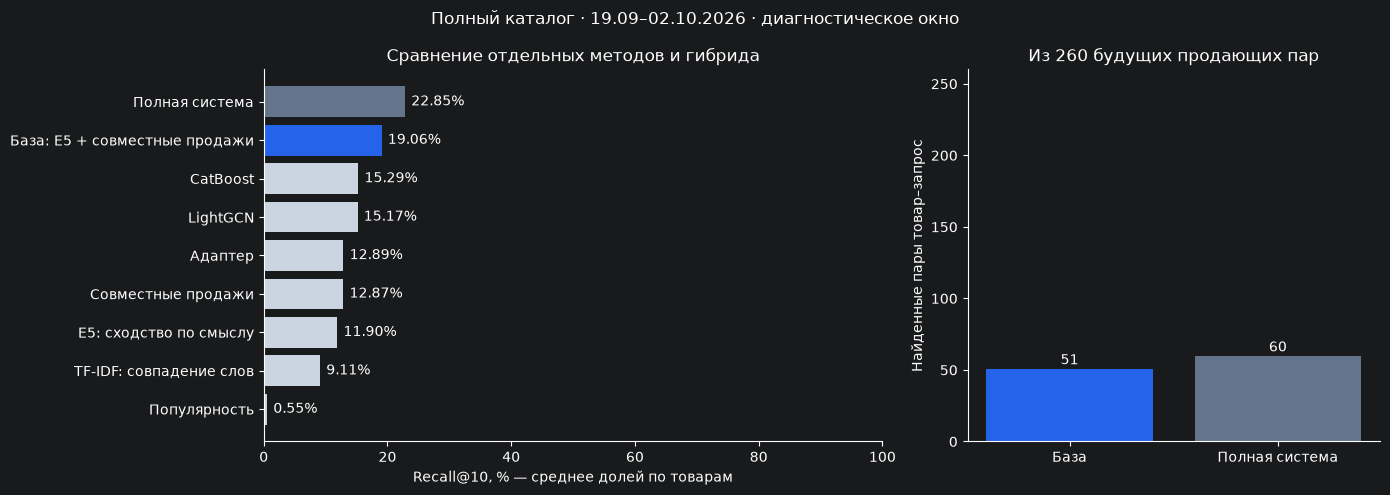

,"Recall@10, %",NDCG@10,Источник
Вариант,,,
Полная система,22.8486,0.1622,Позиции из CSV
База: E5 + совместные продажи,19.0584,0.1327,Позиции из CSV
CatBoost,15.2922,0.0964,Сохранённые метрики
LightGCN,15.1666,0.1024,Сохранённые метрики
Адаптер,12.8926,0.0932,Сохранённые метрики
Совместные продажи,12.8680,0.0976,Сохранённые метрики
E5: сходство по смыслу,11.8959,0.0767,Сохранённые метрики
TF-IDF: совпадение слов,9.1116,0.0520,Сохранённые метрики
Популярность,0.5510,0.0025,Сохранённые метрики


Recall — среднее долей по товарам; число найденных пар показано отдельно. Все цели учтены.
Продажи не измерялись: оценивается ранжирование запросов.


In [3]:
def repeat_result_summary(report):
    controls = [row['Recall@10, %'] for row in report['ablation']
                if row['Вариант'] == 'База: E5 + co-sales']
    rows = report['seeds']
    if len(controls) != 1 or len(rows) < 2 or len({row['seed'] for row in rows}) != len(rows):
        raise ValueError('Нужны одна база и минимум два разных seed без отбора запусков.')
    baseline = float(controls[0])
    scores = np.asarray([row['Recall@10, %'] for row in rows], dtype=float)
    if (not np.isfinite(baseline) or not 0 <= baseline <= 100
            or not np.isfinite(scores).all() or ((scores < 0) | (scores > 100)).any()):
        raise ValueError('Recall должен быть конечным процентом от 0 до 100.')
    return {'baseline': baseline, 'count': len(rows), 'mean': float(scores.mean()),
            'std': float(scores.std(ddof=1)), 'gain': float(scores.mean() - baseline),
            'minimum': float(scores.min()), 'maximum': float(scores.max()),
            'wins': int((scores > baseline).sum()), 'losses': int((scores < baseline).sum()),
            'ties': int((scores == baseline).sum())}


method_names = {'lexical': 'TF-IDF: совпадение слов', 'co_sales': 'Совместные продажи',
    'pretrained_embeddings': 'E5: сходство по смыслу', 'semantic_adapter': 'Адаптер',
    'lightgcn': 'LightGCN', 'popularity': 'Популярность', 'catboost_pu': 'CatBoost',
    'learned_fusion': 'Полная система', 'e5_co_sales': 'База: E5 + совместные продажи'}
comparison_rows = []
for method, metric in summary_report['test']['models'].items():
    reference = real_metrics['system'] if method == 'learned_fusion' else metric
    comparison_rows.append({'method': method, 'Вариант': method_names.get(method, method),
        'Recall@10, %': 100 * reference['recall@10'], 'NDCG@10': reference['ndcg@10'],
        'Источник': 'Позиции из CSV' if method == 'learned_fusion' else 'Сохранённые метрики'})
comparison_rows.append({'method': 'e5_co_sales', 'Вариант': method_names['e5_co_sales'],
    'Recall@10, %': 100 * real_metrics['baseline']['recall@10'],
    'NDCG@10': real_metrics['baseline']['ndcg@10'], 'Источник': 'Позиции из CSV'})
full_comparison = pd.DataFrame(comparison_rows).set_index('method').sort_values('Recall@10, %', ascending=False)
assert set(full_comparison.index) == set(summary_report['test']['models']) | {'e5_co_sales'}

display(Markdown('**Дополнительное сравнение методов.** Диагностическое окно 19.09–02.10: '
    'полный каталог, общий пул, 121 товар и 260 продающих пар.'))
fig, axes = plt.subplots(1, 2, figsize=(14, 5), gridspec_kw={'width_ratios': [1.5, 1]})
colors = ['#64748b' if method == 'learned_fusion' else '#2563eb' if method == 'e5_co_sales'
          else '#cbd5e1' for method in full_comparison.index]
bars = axes[0].barh(full_comparison['Вариант'], full_comparison['Recall@10, %'], color=colors)
axes[0].invert_yaxis()
axes[0].set_xlim(0, 100)
axes[0].set_title('Сравнение отдельных методов и гибрида')
axes[0].set_xlabel('Recall@10, % — среднее долей по товарам')
for bar, value in zip(bars, full_comparison['Recall@10, %']):
    axes[0].text(value + 1, bar.get_y() + bar.get_height() / 2, f'{value:.2f}%', va='center')
hits = [real_metrics[name]['hits'] for name in ['baseline', 'system']]
bars = axes[1].bar(['База', 'Полная система'], hits, color=['#2563eb', '#64748b'])
axes[1].set_ylim(0, len(real_test))
axes[1].set_ylabel('Найденные пары товар–запрос')
axes[1].set_title(f'Из {len(real_test)} будущих продающих пар')
for bar, value in zip(bars, hits):
    axes[1].text(bar.get_x() + bar.get_width() / 2, value + 3, str(value), ha='center')
for ax in axes:
    ax.spines[['top', 'right']].set_visible(False)
fig.suptitle('Полный каталог · 19.09–02.10.2026 · диагностическое окно')
fig.tight_layout()
plt.show()
plt.close(fig)
display(full_comparison[['Вариант', 'Recall@10, %', 'NDCG@10', 'Источник']].set_index('Вариант').round(4))
print('Recall — среднее долей по товарам; число найденных пар показано отдельно. Все цели учтены.')
print('Продажи не измерялись: оценивается ранжирование запросов.')

### Примеры ранжирования

Показаны оба случая: система поднимает будущий продающий запрос в первые десять и, наоборот, теряет попадание базы. `P…` и `Q…` — обезличенные номера товара и кластера.

CSV содержит все 260 будущих продающих пар. «Не найден» означает отсутствие в пуле; такая цель учитывается как пропуск. Примеры ниже иллюстрируют результат, а не заменяют расчёт по всей выборке.

In [4]:
baseline_hit = real_test['baseline_rank'].le(10).fillna(False)
system_hit = real_test['system_rank'].le(10).fillna(False)
gained = real_test.loc[system_hit & ~baseline_hit]
lost = real_test.loc[baseline_hit & ~system_hit]
shared = int((baseline_hit & system_hit).sum())
neither = int((~baseline_hit & ~system_hit).sum())
print(f'Система нашла, база пропустила: {len(gained)} пар.')
print(f'База нашла, система пропустила: {len(lost)} пар.')
print(f'Нашли оба: {shared}. Не попали в первые 10 ни у одного: {neither}.')
assert len(gained) + len(lost) + shared + neither == len(real_test)

example_pairs = pd.concat([
    gained.head(3).assign(Итог='Выигрыш системы'),
    lost.head(3).assign(Итог='Потеря системы'),
])


def readable_rank(value):
    if pd.isna(value):
        return 'Не найден'
    return f'{int(value)} — в первых 10' if value <= 10 else f'{int(value)} — вне первых 10'


example_table = example_pairs[['product_id', 'query_id', 'Итог']].rename(
    columns={'product_id': 'Товар', 'query_id': 'Запрос'})
example_table['Место у базы'] = example_pairs['baseline_rank'].map(readable_rank)
example_table['Место у системы'] = example_pairs['system_rank'].map(readable_rank)
example_table['Заказ в следующие 14 дней'] = 'Да'
display(example_table.set_index(['Товар', 'Запрос']))
print('Примеры из полного 14-дневного окна 19.09–02.10.')

Система нашла, база пропустила: 16 пар.
База нашла, система пропустила: 7 пар.
Нашли оба: 44. Не попали в первые 10 ни у одного: 193.


,,Итог,Место у базы,Место у системы,Заказ в следующие 14 дней
Товар,Запрос,,,,
P0030,Q0019,Выигрыш системы,15 — вне первых 10,3 — в первых 10,Да
P0047,Q0017,Выигрыш системы,80 — вне первых 10,10 — в первых 10,Да
P0049,Q0152,Выигрыш системы,15 — вне первых 10,8 — в первых 10,Да
P0007,Q0321,Потеря системы,5 — в первых 10,12 — вне первых 10,Да
P0013,Q0323,Потеря системы,4 — в первых 10,29 — вне первых 10,Да
P0020,Q0307,Потеря системы,3 — в первых 10,13 — вне первых 10,Да


Примеры из полного 14-дневного окна 19.09–02.10.


## Анализ данных и диагностика обучения

Дополнительные эксперименты проверяют выбор эпохи, вклад каналов, чувствительность к настройкам и искажениям данных. Для многократных контролируемых обучений используется сокращённый каталог со своей базой сравнения. Его результаты рассматриваются отдельно от основного эксперимента на полном каталоге.

Расчёты запускаются автоматически при наличии входов из `config.json`; проверенные результаты повторно используются по контрольным суммам. Без приватных файлов доступны сохранённые обезличенные таблицы и графики.

In [5]:
from datetime import date
from time import perf_counter
import torch
from cluster_data import dictionary_snapshot, aggregate_clusters, period_pairs, future_positives, sha256
from cluster_recommender import HybridRetriever, load_embeddings, lexical_index
from full_history_recommender import DormantConfig, dormant_positives, enrich_candidates
from dormant_learning import ranking_metrics, learning_rows, fit_ranker, predict_ranker
from semantic_adapter import fit_adapter, apply_adapter
from graph_learning import fit_graph
from automatic_check import study_cache_valid

ROOT = SUMMARY_ROOT
torch.set_num_threads(2)
research_path = ROOT / 'reports/notebook_research.json'
research_config = json.loads((ROOT / 'config.json').read_text())
RECOMPUTE_RESEARCH = all((ROOT / research_config['inputs'][key]).is_file()
                         for key in ['facts', 'dictionary', 'embeddings']) and not study_cache_valid(ROOT)
research = {} if RECOMPUTE_RESEARCH else json.loads(research_path.read_text())
if RECOMPUTE_RESEARCH:
    print('Автоматический пересчёт: нет проверенного кэша или изменились входы, код либо библиотеки.')
    facts = pd.read_csv(ROOT / research_config['inputs']['facts'],
                        dtype={'sku': 'string', 'query': 'string'}, keep_default_na=False)
    dictionary = pd.read_csv(ROOT / research_config['inputs']['dictionary'], keep_default_na=False)
    dictionary_time = pd.Timestamp('2026-06-26T23:59:59.999999999Z')
    real_snapshot, dictionary_audit = dictionary_snapshot(dictionary, dictionary_time)
    real_daily, mapping_audit = aggregate_clusters(facts, real_snapshot)
    real_catalog = sorted(real_snapshot.normquery.unique())
    real_vectors, embedding_metadata = load_embeddings(ROOT / research_config['inputs']['embeddings'], real_catalog)
    assert pd.Timestamp(embedding_metadata['dictionary_as_of']) == dictionary_time
    real_text = lexical_index(real_catalog)
    research['provenance'] = {key: sha256(ROOT / research_config['inputs'][key])
                              for key in ['facts', 'dictionary', 'embeddings']}
    print('Фактов:', len(facts), '| SKU:', facts.sku.nunique(), '| кластеров:', len(real_catalog))
    print('Нормализованных дневных строк:', len(real_daily), '| E5:', real_vectors.shape)
else:
    print('Читаются сохранённые реальные расчёты. При наличии приватных входов проверены их хеши, код и библиотеки.')

Автоматический пересчёт: нет проверенного кэша или изменились входы, код либо библиотеки.
Фактов: 3203109 | SKU: 2171 | кластеров: 477579
Нормализованных дневных строк: 1358760 | E5: (477579, 384)


### Данные и нормализация запросов

| Поле | Значение после агрегации |
|---|---|
| `orders` | Сумма заказов пары товар–кластер. |
| `views` | Сумма дневных `unique_view_users` по фразам кластера, не уникальные люди за всё окно. |
| `searches` | Сумма дневных поисковых счётчиков без дублирования спроса по товарам. |
| `days` | Число наблюдавшихся дат пары, не длина окна. |

Отсутствующие даты считаются пробелами, а не нулями. **Неполные целевые окна не оцениваются.** Выбросы отмечаются правилом IQR без удаления; при IQR = 0 даже единица может попасть в эту группу.

Проверены покрытие словаря, конфликты и некорректные записи. Смысловая точность нормализации не измерена: экспертной разметки нет. Категорийных меток нет, поэтому срезы строятся по объёму прошлой продающей истории.

100 наблюдавшихся соответствий: data/notebook_normalization_observed_review.csv (приватный файл).
Разметка correct: 1 = верно, 0 = ошибка, ? = неоднозначно; пусто = не проверено.
Реальная выгрузка: 3203109 строк; 2171 SKU.
Дни без выгрузки: 2026-05-19, 2026-06-04, 2026-06-12, 2026-07-21
Дубли ключа: 0 | заказы без просмотров: 11285


,Поле,NULL,Пустая строка
0,date,0,0
1,sku,0,0
2,query,0,0
3,unique_search_users,0,0
4,unique_view_users,0,0
5,order_count,0,0


,field,zeros_pct,median,p95,p99,max,iqr_fence,above_fence
0,order_count,95.231,0.0,0.0,1.0,98.0,0.0,152751
1,unique_view_users,0.352,1.0,17.0,79.0,2930.0,6.0,383904
2,unique_search_users,0.687,5.0,1020.0,5584.0,42544.0,101.0,564054


,"Покрытие строк, %","Покрытие уникальных запросов, %","Покрытие заказов, %",Конфликтующих соответствий,Невалидных записей,Будущих записей исключено
0,58.93,9.15,82.24,13793,39553,0


,sample_size,decided,uncertain,unreviewed,accuracy_on_decided,wilson_95_on_decided,complete,sampling_unit
0,100,0,0,100,None,None,False,"uniform observed mapped query, not orders-weig..."


При незаполненной или частичной разметке точность всей нормализации не заявляется.


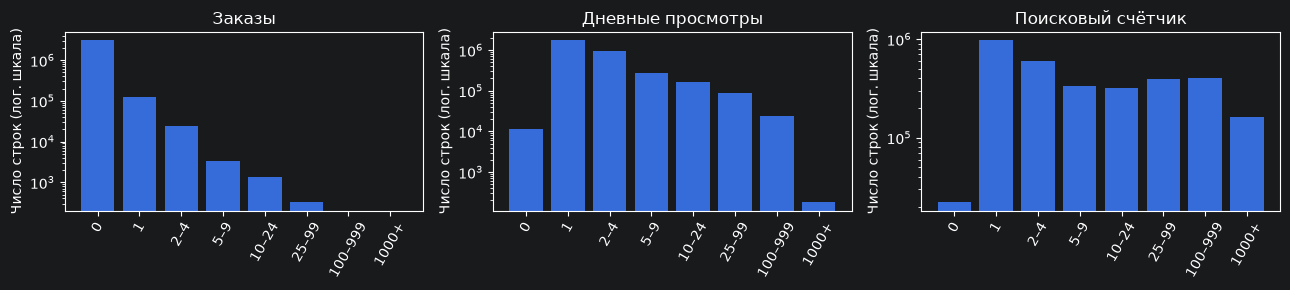

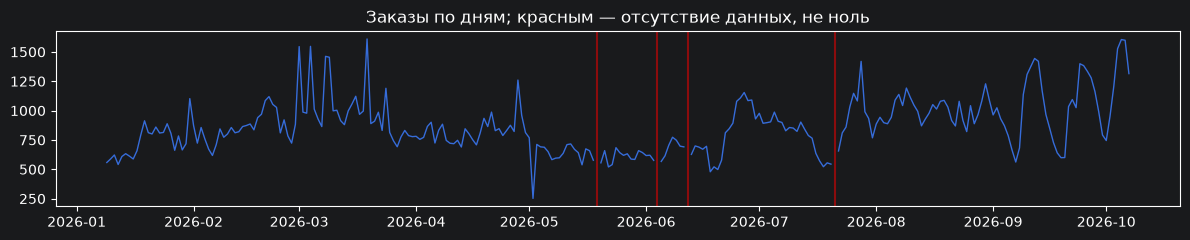

In [6]:
from notebook_research import data_overview, profile_scorer, tune_fusion, semantic_review_sample, semantic_review_summary
import matplotlib.pyplot as plt

if RECOMPUTE_RESEARCH:
    research['eda'] = data_overview(facts, real_snapshot)
    research['normalization'] = {**dictionary_audit,
        'selection': 'Последнее успешное соответствие; при равных датах — лексикографически последний кластер',
        'order_coverage_pct': 100 * mapping_audit['order_coverage'],
        'semantic_accuracy': None, 'review_status': 'awaiting_expert_labels'}
    audit_sample = semantic_review_sample(facts, real_snapshot, size=100, seed=7)
    private_audit = ROOT / 'data/notebook_normalization_observed_review.csv'
    if not private_audit.exists():
        audit_sample.to_csv(private_audit, index=False)
    reviewed_sample = pd.read_csv(private_audit, keep_default_na=False)
    research['semantic_review'] = semantic_review_summary(reviewed_sample, audit_sample)
    print('100 наблюдавшихся соответствий: data/notebook_normalization_observed_review.csv (приватный файл).')
    print('Разметка correct: 1 = верно, 0 = ошибка, ? = неоднозначно; пусто = не проверено.')

eda = research['eda']
print('Реальная выгрузка:', eda['rows'], 'строк;', eda['skus'], 'SKU.')
print('Дни без выгрузки:', ', '.join(eda['missing_days']))
print('Дубли ключа:', eda['duplicate_keys'], '| заказы без просмотров:', eda['orders_without_views_rows'])
display(pd.DataFrame(eda['fields']).rename(columns={'field': 'Поле', 'missing': 'NULL', 'blank': 'Пустая строка'}))
display(pd.DataFrame(eda['distributions']).round(3))
normalization = research['normalization']
display(pd.DataFrame([{
    'Покрытие строк, %': eda['row_mapping_pct'], 'Покрытие уникальных запросов, %': eda['query_mapping_pct'],
    'Покрытие заказов, %': normalization['order_coverage_pct'],
    'Конфликтующих соответствий': normalization['ambiguous_queries'],
    'Невалидных записей': normalization['invalid_historical_rows'],
    'Будущих записей исключено': normalization['future_rows_ignored'],
}]).round(2))
display(pd.DataFrame([research['semantic_review']]))
print('При незаполненной или частичной разметке точность всей нормализации не заявляется.')

fig, axes = plt.subplots(1, 3, figsize=(13, 3))
for ax, column, title in zip(axes, ['order_count', 'unique_view_users', 'unique_search_users'],
                             ['Заказы', 'Дневные просмотры', 'Поисковый счётчик']):
    ax.bar(['0', '1', '2–4', '5–9', '10–24', '25–99', '100–999', '1000+'], eda['histograms'][column])
    ax.set_yscale('log'); ax.set_title(title); ax.tick_params(axis='x', rotation=60)
    ax.set_ylabel('Число строк (лог. шкала)')
fig.tight_layout(); plt.show(); plt.close(fig)
calendar = pd.DataFrame(eda['daily']).assign(date=lambda frame: pd.to_datetime(frame.date))
fig, ax = plt.subplots(figsize=(12, 2.5))
ax.plot(calendar.date, calendar.orders, linewidth=1)
for missing in eda['missing_days']:
    ax.axvline(pd.Timestamp(missing), color='red', alpha=.5)
ax.set_title('Заказы по дням; красным — отсутствие данных, не ноль')
fig.tight_layout(); plt.show(); plt.close(fig)

### Временное разделение диагностических экспериментов

Каталог ограничен запросами, наблюдавшимися до **21.08**, и словарём от **26.06**. TF-IDF строится только по доступному каталогу.

| Период | Назначение |
|---|---|
| По 21.08 | Обучение нейросетей |
| 22.08–04.09 | Выбор эпохи |
| 05–18.09 | Выбор архитектуры и весов |
| 19.09–02.10 | Диагностика фиксированных настроек |

Это отдельная диагностическая схема, не временное разделение основного эксперимента. Целевые окна не пересекаются; для выбора эпохи кандидаты строятся без обучаемых каналов. Во всех оценках сохраняются ненайденные цели.

Для расчёта нужны полные 14 дней истории и 14 целевых дней. Горизонты 7/14/28 сравниваются только как разные постановки задачи.

In [7]:
if RECOMPUTE_RESEARCH:
    study_catalog = sorted(real_daily.loc[real_daily.date.le('2026-08-21'), 'normquery'].unique())
    catalog_positions = pd.Index(real_catalog).get_indexer(study_catalog)
    assert (catalog_positions >= 0).all()
    study_vectors = real_vectors[catalog_positions].copy()
    study_text = lexical_index(study_catalog)
    study_daily = real_daily.loc[real_daily.normquery.isin(study_catalog)].copy()
    study_config = DormantConfig(date(2026, 6, 26), date(2026, 6, 26),
        date(2026, 9, 4), date(2026, 9, 18), per_source=50, iterations=(40, 100, 300))
    source_days = pd.DatetimeIndex(pd.to_datetime(facts.date).unique())

    def study_split(decision, horizon=14, max_views=5, per_source=50, frame=None):
        cutoff = pd.Timestamp(decision)
        frame = study_daily if frame is None else frame
        history = period_pairs(frame, frame.date.min().date(), cutoff.date())
        recent = period_pairs(frame, (cutoff - pd.Timedelta(days=13)).date(), cutoff.date())
        full_recent = period_pairs(real_daily, (cutoff - pd.Timedelta(days=13)).date(), cutoff.date())
        required_days = pd.date_range(cutoff - pd.Timedelta(days=13), cutoff + pd.Timedelta(days=horizon))
        assert required_days.difference(source_days).empty, 'Неполное окно не оцениваем'
        active = set(full_recent.sku)
        part = frame.loc[frame.date.between(cutoff - pd.Timedelta(days=13), cutoff)]
        demand = part.drop_duplicates(['date', 'normquery']).groupby('normquery').cluster_searches.sum()
        base = HybridRetriever(study_catalog, history, demand, study_vectors, study_text).generate(
            per_source, max_history_views=max_views, traffic_history=recent, target_skus=active, max_seeds=32)
        full_history = period_pairs(real_daily, real_daily.date.min().date(), cutoff.date())
        future = period_pairs(real_daily, (cutoff + pd.Timedelta(days=1)).date(),
                              (cutoff + pd.Timedelta(days=horizon)).date())
        targets = dormant_positives(future_positives(full_history, future), full_recent, max_views, active)
        return {'base': base, 'history': history, 'recent': recent, 'demand': demand,
                'active': active, 'targets': targets, 'decision': decision}

    splits = {}
    for name, day in [('epoch_validation', '2026-08-21'), ('validation', '2026-09-04'), ('test', '2026-09-18')]:
        started = perf_counter()
        splits[name] = study_split(day)
        print(name, ': поиск выполнен за', round(perf_counter() - started, 1), 'с')
    neural_history = splits['epoch_validation']['history']
    research['study'] = {'catalog_clusters': len(study_catalog), 'full_catalog_clusters': len(real_catalog),
        'train_skus': int(neural_history.sku.nunique()), 'train_end': '2026-08-21',
        'per_source': 50, 'seeds': [7, 17, 27, 37, 47], 'status': 'reused_diagnostic_period',
        'splits': [{'name': name, 'decision': part['decision'], 'candidates': len(part['base']),
                    'target_skus': int(part['targets'].sku.nunique()), 'targets': len(part['targets']),
                    'targets_outside_catalog': int((~part['targets'].normquery.isin(study_catalog)).sum())}
                   for name, part in splits.items()]}
print('Каталог исследования:', research['study']['catalog_clusters'],
      'из', research['study']['full_catalog_clusters'], 'кластеров полного релиза.')
display(pd.DataFrame(research['study']['splits']))

epoch_validation : поиск выполнен за 5.0 с
validation : поиск выполнен за 4.9 с
test : поиск выполнен за 4.9 с
Каталог исследования: 18444 из 477579 кластеров полного релиза.


,name,decision,candidates,target_skus,targets,targets_outside_catalog
0,epoch_validation,2026-08-21,47668,113,231,23
1,validation,2026-09-04,46760,104,228,18
2,test,2026-09-18,42900,121,260,48


### Обучение и выбор эпохи

Обучение ограничено 40 эпохами. После пяти проверок без улучшения NDCG@10 на 0,0001 оно останавливается (`patience = 5`, `min_delta = 0,0001`). Восстанавливаются веса с наибольшей отложенной метрикой, включая эпоху 0.

Графики показывают ошибку обучения и качество на отдельном периоде; таблица — число эпох и шагов оптимизатора. Эти контрольные кривые описывают ход обучения. Архитектуры сравниваются по нескольким seed в разделе подбора настроек.

Короткая проверка adapter : отложенная метрика вычислена, оценки конечны.
Короткая проверка graph : отложенная метрика вычислена, оценки конечны.
adapter {'hidden_dim': 128} : лучшая эпоха 1 , шагов 954
adapter {'hidden_dim': 64} : лучшая эпоха 1 , шагов 954
graph {'dimensions': 32, 'layers': 2} : лучшая эпоха 11 , шагов 15
graph {'dimensions': 16, 'layers': 2} : лучшая эпоха 3 , шагов 8
graph {'dimensions': 32, 'layers': 1} : лучшая эпоха 7 , шагов 12


,model,hidden_dim,best_epoch,epochs_completed,optimizer_steps,validation_ndcg@10,validation_recall@10,seconds,dimensions,layers
0,adapter,128.0,1,6,954,0.0714,0.1163,5.8436,NaN,NaN
1,adapter,64.0,1,6,954,0.0747,0.1307,5.3224,NaN,NaN
2,graph,NaN,11,15,15,0.1161,0.2013,2.0517,32.0,2.0
3,graph,NaN,3,8,8,0.1135,0.1682,1.1823,16.0,2.0
4,graph,NaN,7,12,12,0.0928,0.1508,1.6827,32.0,1.0


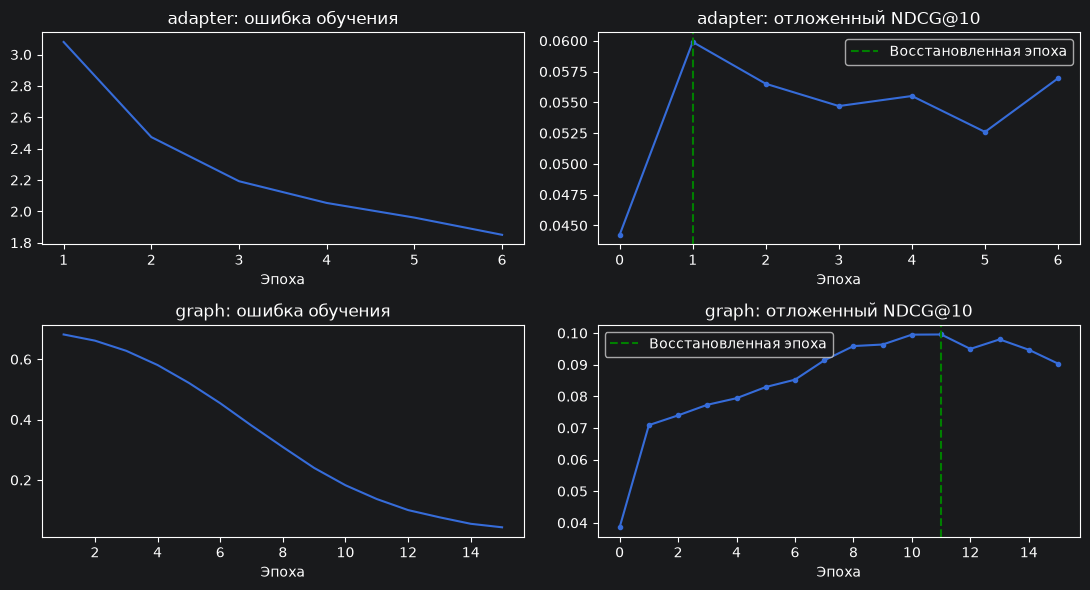

Параметры контрольных кривых: {'adapter': {'hidden_dim': 64}, 'graph': {'dimensions': 32, 'layers': 2}}


In [8]:
if RECOMPUTE_RESEARCH:
    stop_split = splits['epoch_validation']
    adapter_scorer = profile_scorer(stop_split['base'], stop_split['history'], study_catalog, weighted=True)
    graph_scorer = profile_scorer(stop_split['base'], stop_split['history'], study_catalog, weighted=False)
    assert not stop_split['targets'].empty

    def stop_metric(scores):
        prediction = stop_split['base'][['sku', 'normquery']].assign(score=scores)
        return ranking_metrics(prediction, stop_split['targets'])['ndcg@10']

    def train_network(kind, seed=7, epochs=40, hidden_dim=128, dimensions=32, layers=2, history=None):
        history = neural_history if history is None else history
        started = perf_counter()
        options = dict(epochs=epochs, seed=seed, train_end='2026-08-21',
                       patience=5, min_delta=.0001, selection_metric='future NDCG@10: 22.08–04.09')
        if kind == 'adapter':
            model, audit = fit_adapter(history, study_catalog, study_vectors, batch_size=128,
                hidden_dim=hidden_dim, device='cpu',
                validation_callback=lambda current: stop_metric(adapter_scorer(apply_adapter(current, study_vectors))),
                **options)
            encoded = apply_adapter(model, study_vectors)
        else:
            model, audit = fit_graph(history, study_catalog, dimensions=dimensions, layers=layers,
                validation_callback=lambda current: stop_metric(graph_scorer(current.query_vectors(study_catalog)[0])),
                **options)
            encoded = model.query_vectors(study_catalog)[0]
        assert np.isfinite(encoded).all() and len(audit['validation_per_epoch']) == audit['epochs_completed'] + 1
        audit['seconds'] = perf_counter() - started
        return encoded, audit, model

    for kind in ['adapter', 'graph']:
        smoke_vectors, smoke_audit, _ = train_network(kind, epochs=1)
        assert smoke_audit['optimizer_steps'] > 0 and smoke_audit['best_validation_score'] is not None
        print('Короткая проверка', kind, ': отложенная метрика вычислена, оценки конечны.')
    architectures = [('adapter', {'hidden_dim': 128}), ('adapter', {'hidden_dim': 64}),
                     ('graph', {'dimensions': 32, 'layers': 2}),
                     ('graph', {'dimensions': 16, 'layers': 2}), ('graph', {'dimensions': 32, 'layers': 1})]
    architecture_results = []
    trained_architectures = []
    validation_base = splits['validation']['base']
    for kind, parameters in architectures:
        encoded, audit, model = train_network(kind, **parameters)
        score = profile_scorer(validation_base, splits['validation']['history'], study_catalog,
                               weighted=kind == 'adapter')(encoded)
        metric = ranking_metrics(validation_base[['sku', 'normquery']].assign(score=score), splits['validation']['targets'])
        record = {'model': kind, **parameters, 'best_epoch': audit['best_epoch'],
                  'epochs_completed': audit['epochs_completed'], 'optimizer_steps': audit['optimizer_steps'],
                  'validation_ndcg@10': metric['ndcg@10'], 'validation_recall@10': metric['recall@10'],
                  'seconds': audit['seconds']}
        architecture_results.append(record)
        trained_architectures.append((encoded, audit, model))
        print(kind, parameters, ': лучшая эпоха', audit['best_epoch'], ', шагов', audit['optimizer_steps'])
    selected_architectures = {kind: max([i for i, value in enumerate(architectures) if value[0] == kind],
                              key=lambda i: architecture_results[i]['validation_ndcg@10']) for kind in ['adapter', 'graph']}
    selected_vectors = {kind: trained_architectures[index][0] for kind, index in selected_architectures.items()}
    research['architecture'] = architecture_results
    research['selected_parameters'] = {kind: architectures[index][1] for kind, index in selected_architectures.items()}
    research['curves'] = {kind: {key: trained_architectures[index][1][key] for key in
        ['validation_per_epoch', 'epochs_completed', 'best_epoch', 'optimizer_steps']} |
        {'loss': trained_architectures[index][1]['loss_per_epoch' if kind == 'adapter' else 'bpr_losses']}
        for kind, index in selected_architectures.items()}

display(pd.DataFrame(research['architecture']).round(4))
fig, axes = plt.subplots(2, 2, figsize=(11, 6))
for row, kind in enumerate(['adapter', 'graph']):
    curve = research['curves'][kind]
    axes[row, 0].plot(range(1, len(curve['loss']) + 1), curve['loss'])
    axes[row, 0].set_title(kind + ': ошибка обучения')
    axes[row, 1].plot(range(len(curve['validation_per_epoch'])), curve['validation_per_epoch'], marker='.')
    axes[row, 1].axvline(curve['best_epoch'], color='green', linestyle='--', label='Восстановленная эпоха')
    axes[row, 1].set_title(kind + ': отложенный NDCG@10')
    axes[row, 1].legend()
    for ax in axes[row]:
        ax.set_xlabel('Эпоха')
fig.tight_layout()
plt.show()
plt.close(fig)
print('Параметры контрольных кривых:', research['selected_parameters'])

### Вклад каналов и веса

Сравниваются база E5 + совместные продажи, добавление адаптера, LightGCN и обеих моделей. Контроль с четырьмя каналами объединяет E5, совместные продажи, TF-IDF и популярность — без обучения новых моделей на этих данных. CatBoost оценивается отдельно.

**Общий пул** проверяет ранжирование; **собственный поиск** — также полноту подбора кандидатов. Одинаковый лимит на источник не означает одинаковый суммарный бюджет.

Разрыв NDCG между настройкой и следующим периодом: **0,0203** для равных весов, **0,0588** для 35 сочетаний и **0,0494** для 286. Обе сетки хуже переносят настроечный результат, хотя зависимость не строго монотонна.

В основном эксперименте используются равные фиксированные веса, **без нового поиска весов**. Диагностическое окно не выбирает победителя среди сеток.

In [9]:
from dormant_learning import fit_fusion, fusion_scores, ranking_metrics
from full_history_recommender import bootstrap_difference

variants = {
    'База: E5 + co-sales': ['pretrained_embeddings', 'co_sales'],
    'База + адаптер': ['pretrained_embeddings', 'co_sales', 'semantic_adapter'],
    'База + LightGCN': ['pretrained_embeddings', 'co_sales', 'lightgcn'],
    'Полные четыре': ['pretrained_embeddings', 'co_sales', 'semantic_adapter', 'lightgcn'],
    'Четыре без обучения': ['pretrained_embeddings', 'co_sales', 'lexical', 'popularity'],
}
source_by_channel = {'pretrained_embeddings': 'embedding', 'co_sales': 'graph',
    'semantic_adapter': 'adapter', 'lightgcn': 'lightgcn', 'lexical': 'text', 'popularity': 'popular'}

if RECOMPUTE_RESEARCH:
    def expanded_pool(part, encoded):
        return enrich_candidates(part['base'], part['history'], part['recent'], part['demand'],
            study_catalog, study_vectors, encoded['adapter'], encoded['graph'],
            study_text, study_config, part['active'])

    common_pools = {name: expanded_pool(part, selected_vectors) for name, part in splits.items()}
    chosen_fusions = {}
    ablation_rows = []
    retrieval_rows = []
    common_test = common_pools['test']
    common_targets = splits['test']['targets']
    for name, channel_names in variants.items():
        chosen = fit_fusion(common_pools['validation'], splits['validation']['targets'], channel_names)
        chosen_fusions[name] = chosen
        scores = fusion_scores(common_test, chosen['weights'])
        metric = ranking_metrics(common_test[['sku', 'normquery']].assign(score=scores), common_targets)
        ablation_rows.append({'Вариант': name, 'Recall@10, %': 100 * metric['recall@10'],
            'NDCG@10': metric['ndcg@10'], 'Validation NDCG@10': max(t['metrics']['ndcg@10'] for t in chosen['trials']),
            'Проверено весов': len(chosen['trials']), 'Веса': chosen['weights']})
        allowed_sources = {source_by_channel[channel] for channel in channel_names}
        own_pool = common_test.loc[common_test.retrieval_sources.map(
            lambda value: bool(set(value.split(',')) & allowed_sources))].copy()
        own_scores = fusion_scores(own_pool, chosen['weights'])
        own_metric = ranking_metrics(own_pool[['sku', 'normquery']].assign(score=own_scores), common_targets)
        retrieval_rows.append({'Вариант': name, 'Пул': len(own_pool),
            'Retrieval recall, %': 100 * own_metric['retrieval_recall'],
            'Recall@10, %': 100 * own_metric['recall@10'], 'NDCG@10': own_metric['ndcg@10']})
    equal_channels = variants['Четыре без обучения']
    equal_scores = fusion_scores(common_test, {channel: .25 for channel in equal_channels})
    equal_metric = ranking_metrics(common_test[['sku', 'normquery']].assign(score=equal_scores), common_targets)
    ablation_rows.append({'Вариант': 'Четыре без обучения: равные веса',
                          'Recall@10, %': 100 * equal_metric['recall@10'], 'NDCG@10': equal_metric['ndcg@10'],
                          'Проверено весов': 0, 'Веса': {channel: .25 for channel in equal_channels}})
    research['ablation'] = ablation_rows
    research['retrieval_ablation'] = retrieval_rows
    research['weights'] = {name: value['weights'] for name, value in chosen_fusions.items()}
    full_scores = fusion_scores(common_test, chosen_fusions['Полные четыре']['weights'])
    base_scores = fusion_scores(common_test, chosen_fusions['База: E5 + co-sales']['weights'])
    research['interval'] = bootstrap_difference(common_test, common_targets, full_scores, base_scores)

print('Ранжирование на общем пуле:')
display(pd.DataFrame(research['ablation']).drop(columns='Веса').round(4))
print('Собственный поиск каждого варианта:')
display(pd.DataFrame(research['retrieval_ablation']).round(3))
interval = research['interval']
print('Полная модель минус база:', round(100 * interval['difference'], 2), 'п.п.; 95% интервал:',
      [round(100 * interval[key], 2) for key in ['lower', 'upper']])

Ранжирование на общем пуле:


,Вариант,"Recall@10, %",NDCG@10,Validation NDCG@10,Проверено весов
0,База: E5 + co-sales,17.5354,0.1165,0.1216,5
1,База + адаптер,19.0506,0.1247,0.1270,15
2,База + LightGCN,18.0077,0.1182,0.1454,15
3,Полные четыре,15.7113,0.0941,0.1529,35
4,Четыре без обучения,13.8085,0.0998,0.1249,35
5,Четыре без обучения: равные веса,11.6952,0.0805,NaN,0


Собственный поиск каждого варианта:


,Вариант,Пул,"Retrieval recall, %","Recall@10, %",NDCG@10
0,База: E5 + co-sales,24544,42.161,17.130,0.115
1,База + адаптер,26772,45.329,17.957,0.121
2,База + LightGCN,32904,50.877,18.008,0.118
3,Полные четыре,34966,51.566,15.700,0.095
4,Четыре без обучения,42900,47.560,13.602,0.099


Полная модель минус база: -1.82 п.п.; 95% интервал: [-6.14, 2.33]


In [10]:
print('Веса, выбранные до диагностического test:')
display(pd.DataFrame(research['weights']).T.fillna(0).round(2))
print('Названия вариантов задают разрешённые каналы; validation может присвоить некоторым нулевой вес.')
print('Нулевой вес не означает, что канал отдельно доказанно бесполезен: это результат данного окна и сетки.')

Веса, выбранные до диагностического test:


,pretrained_embeddings,co_sales,semantic_adapter,lightgcn,lexical,popularity
База: E5 + co-sales,0.50,0.50,0.00,0.0,0.0,0.00
База + адаптер,0.00,0.50,0.50,0.0,0.0,0.00
База + LightGCN,0.25,0.25,0.00,0.5,0.0,0.00
Полные четыре,0.25,0.00,0.25,0.5,0.0,0.00
Четыре без обучения,0.50,0.25,0.00,0.0,0.0,0.25


Названия вариантов задают разрешённые каналы; validation может присвоить некоторым нулевой вес.
Нулевой вес не означает, что канал отдельно доказанно бесполезен: это результат данного окна и сетки.


### Повторяемость и чувствительность к данным

Пять запусков с seed **7/17/27/37/47** выполняются с одинаковыми архитектурами, весами и целями. Показаны все результаты, их среднее и разброс; лучший запуск не отбирается.

Изменение числа заказов и изменение графа — разные проверки. У бинарного LightGCN связь задаётся условием `orders > 0`, поэтому замена 10 заказов на 12 её не меняет. Пуассоновский шум не создаёт связей из нулей.

Отдельный структурный стресс-тест удаляет, добавляет и заменяет связи. Сравнение с чистыми данными выполняется на одинаковых seed.

Обучение seed 7 завершено.
Обучение seed 17 завершено.
Обучение seed 27 завершено.
Обучение seed 37 завершено.
Обучение seed 47 завершено.
Искажение данных: потеря 10% рёбер — три обучения завершены.
Искажение данных: Poisson заказов — три обучения завершены.


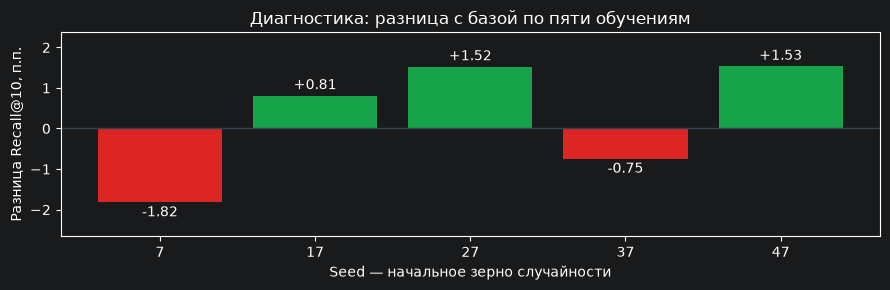

**Диагностика: сокращённый каталог, 19.09–02.10.** Среднее всех 5 запусков: **17.79% против 17.54%** у базы; разница **+0.26 п.п.**, std **1.49 п.п.** Выше базы: 3; ниже: 2; равных: 0. Это среднее метрик отдельных обучений, не ансамбль пяти моделей.

,seed,"Recall@10, %",NDCG@10,"Прирост к базе, п.п.","Собственный поиск Recall@10, %"
0,7,15.7113,0.0941,-1.8241,15.6995
1,17,18.3445,0.1147,0.8091,18.3937
2,27,19.0565,0.1166,1.5211,18.1828
3,37,16.7857,0.1087,-0.7497,17.0691
4,47,19.0676,0.1198,1.5322,21.3404


Разброс по пяти seed:


,"Recall@10, %",NDCG@10,"Прирост к базе, п.п.","Собственный поиск Recall@10, %"
mean,17.7931,0.1108,0.2577,18.1371
std,1.4894,0.0101,1.4894,2.0863
min,15.7113,0.0941,-1.8241,15.6995
max,19.0676,0.1198,1.5322,21.3404


Recall@10, %                           NDCG@10          \
                         mean     std      min      max    mean     std   
Сценарий                                                                  
Poisson заказов       16.3888  0.1461  16.3039  16.5575  0.1026  0.0042   
потеря 10% рёбер      16.7222  2.0087  14.6383  18.6462  0.1066  0.0107   

                                  
                     min     max  
Сценарий                          
Poisson заказов   0.0996  0.1073  
потеря 10% рёбер  0.0954  0.1167

In [11]:
if RECOMPUTE_RESEARCH:
    def score_on_pool(pool, part, encoded):
        result = pool.copy()
        result['adapter_score'] = profile_scorer(pool, part['history'], study_catalog, weighted=True)(encoded['adapter'])
        result['lightgcn_score'] = profile_scorer(pool, part['history'], study_catalog, weighted=False)(encoded['graph'])
        return result

    repeat_rows = []
    for seed in research['study']['seeds']:
        encoded = {}
        for kind in ['adapter', 'graph']:
            encoded[kind] = selected_vectors[kind] if seed == 7 else train_network(
                kind, seed=seed, **research['selected_parameters'][kind])[0]
        scored = score_on_pool(common_test, splits['test'], encoded)
        score = fusion_scores(scored, research['weights']['Полные четыре'])
        metric = ranking_metrics(scored[['sku', 'normquery']].assign(score=score), common_targets)
        own = expanded_pool(splits['test'], encoded)
        own = own.loc[own.retrieval_sources.map(lambda value: bool(
            set(value.split(',')) & {'embedding', 'graph', 'adapter', 'lightgcn'}))]
        own_metric = ranking_metrics(own[['sku', 'normquery']].assign(
            score=fusion_scores(own, research['weights']['Полные четыре'])), common_targets)
        repeat_rows.append({'seed': seed, 'Recall@10, %': 100 * metric['recall@10'],
            'NDCG@10': metric['ndcg@10'], 'Прирост к базе, п.п.': 100 * metric['recall@10'] - research['ablation'][0]['Recall@10, %'],
            'Собственный поиск Recall@10, %': 100 * own_metric['recall@10']})
        print('Обучение seed', seed, 'завершено.')
    research['seeds'] = repeat_rows
    noise_rows = []
    for scenario in ['потеря 10% рёбер', 'Poisson заказов']:
        for seed in [7, 17, 27]:
            rng = np.random.default_rng(seed)
            damaged = neural_history.copy()
            if scenario == 'потеря 10% рёбер':
                damaged = damaged.loc[~(damaged.orders.gt(0) & (rng.random(len(damaged)) < .1))].copy()
            else:
                damaged['orders'] = rng.poisson(damaged.orders.to_numpy(dtype=float))
            encoded = {kind: train_network(kind, seed=seed, history=damaged,
                         **research['selected_parameters'][kind])[0] for kind in ['adapter', 'graph']}
            scored = score_on_pool(common_test, splits['test'], encoded)
            metric = ranking_metrics(scored[['sku', 'normquery']].assign(
                score=fusion_scores(scored, research['weights']['Полные четыре'])), common_targets)
            noise_rows.append({'Сценарий': scenario, 'seed': seed,
                'Recall@10, %': 100 * metric['recall@10'], 'NDCG@10': metric['ndcg@10']})
        print('Искажение данных:', scenario, '— три обучения завершены.')
    research['training_noise'] = noise_rows

repeats = pd.DataFrame(research['seeds'])
repeat_summary = repeat_result_summary(research)
assert repeats.seed.tolist() == research['study']['seeds'], 'Таблица должна содержать все заданные seed'
repeat_gains = repeats['Recall@10, %'] - repeat_summary['baseline']
np.testing.assert_allclose(repeat_gains, repeats['Прирост к базе, п.п.'])
fig, ax = plt.subplots(figsize=(9, 3))
bars = ax.bar(repeats.seed.astype(str), repeat_gains,
              color=['#16a34a' if gain > 0 else '#dc2626' if gain < 0 else '#94a3b8' for gain in repeat_gains])
ax.axhline(0, color='#334155', linewidth=1)
ax.set_title('Диагностика: разница с базой по пяти обучениям')
ax.set_xlabel('Seed — начальное зерно случайности')
ax.set_ylabel('Разница Recall@10, п.п.')
ax.margins(y=.25)
for bar, gain in zip(bars, repeat_gains):
    ax.text(bar.get_x() + bar.get_width() / 2, gain + (.08 if gain >= 0 else -.08),
            f'{gain:+.2f}', ha='center', va='bottom' if gain >= 0 else 'top')
fig.tight_layout()
plt.show()
plt.close(fig)
display(Markdown(f"**Диагностика: сокращённый каталог, 19.09–02.10.** Среднее всех {repeat_summary['count']} запусков: "
    f"**{repeat_summary['mean']:.2f}% против {repeat_summary['baseline']:.2f}%** у базы; "
    f"разница **{repeat_summary['gain']:+.2f} п.п.**, std **{repeat_summary['std']:.2f} п.п.** "
    f"Выше базы: {repeat_summary['wins']}; ниже: {repeat_summary['losses']}; равных: {repeat_summary['ties']}. "
    'Это среднее метрик отдельных обучений, не ансамбль пяти моделей.'))
display(repeats.round(4))
print('Разброс по пяти seed:')
display(repeats.drop(columns='seed').agg(['mean', 'std', 'min', 'max']).round(4))
noise = pd.DataFrame(research['training_noise'])
display(noise.groupby('Сценарий')[['Recall@10, %', 'NDCG@10']].agg(['mean', 'std', 'min', 'max']).round(4))

### Чувствительность к настройкам

На данных для настройки сравниваются лимиты кандидатов 25/50/100, пороги просмотров 0/5/10, число деревьев CatBoost 40/100/300 и шаги весов 0,25/0,1.

Порог просмотров меняет состав оцениваемых пар, а горизонт 7/14/28 — будущие цели. Поэтому эти строки описывают разные условия задачи; выбор наибольшей метрики между ними некорректен.

In [12]:
if RECOMPUTE_RESEARCH:
    sensitivity_rows = []
    for parameter, values in [('per_source', [25, 50, 100]), ('max_views', [0, 5, 10]), ('horizon', [7, 14, 28])]:
        for value in values:
            started = perf_counter()
            day = '2026-08-21' if parameter == 'horizon' else '2026-09-04'
            part = study_split(day, **{parameter: value})
            scores = fusion_scores(part['base'], research['weights']['База: E5 + co-sales'])
            metric = ranking_metrics(part['base'][['sku', 'normquery']].assign(score=scores), part['targets'])
            sensitivity_rows.append({'Параметр': parameter, 'Значение': value, 'Решение': day,
                'Целей': len(part['targets']), 'SKU': metric['evaluated_skus'], 'Пул': len(part['base']),
                'Recall@10, %': 100 * metric['recall@10'], 'Retrieval recall, %': 100 * metric['retrieval_recall'],
                'Секунд': perf_counter() - started})
    research['sensitivity'] = sensitivity_rows
    grid_rows = []
    for units in [4, 10]:
        started = perf_counter()
        choice = tune_fusion(common_pools['validation'], splits['validation']['targets'], variants['Полные четыре'], units=units)
        grid_rows.append({'Шаг': 1 / units, 'Вариантов': choice['trials'],
            'Validation NDCG@10': choice['ndcg@10'], 'Секунд': perf_counter() - started, 'Веса': choice['weights']})
    research['weight_grid'] = grid_rows

    ranker_split = study_split('2026-08-07')
    ranker_rows, _ = learning_rows(ranker_split['base'], ranker_split['targets'], seed=7)
    tree_rows = []
    fitted_rankers = []
    for trees in [40, 100, 300]:
        started = perf_counter()
        current_ranker = fit_ranker(ranker_rows, iterations=trees, seed=7)
        scores = predict_ranker(current_ranker, splits['validation']['base'])
        metric = ranking_metrics(splits['validation']['base'][['sku', 'normquery']].assign(score=scores),
                                 splits['validation']['targets'])
        tree_rows.append({'Деревьев': trees, 'Validation NDCG@10': metric['ndcg@10'],
                          'Validation Recall@10, %': 100 * metric['recall@10'], 'Секунд': perf_counter() - started})
        fitted_rankers.append(current_ranker)
    best_ranker_index = max(range(len(tree_rows)), key=lambda i: tree_rows[i]['Validation NDCG@10'])
    ranker_test_scores = predict_ranker(fitted_rankers[best_ranker_index], common_test)
    research['catboost_selection'] = tree_rows
    research['catboost_test'] = ranking_metrics(common_test[['sku', 'normquery']].assign(score=ranker_test_scores), common_targets)

    sold_counts = splits['test']['history'].loc[lambda frame: frame.orders.gt(0)].groupby('sku').size()
    sold_counts = sold_counts.reindex(common_targets.sku.unique(), fill_value=0)
    slice_rows = []
    for label, minimum, maximum in [('Нет продающих кластеров в каталоге', 0, 0),
            ('1–5 продающих кластеров', 1, 5), ('6–20 кластеров', 6, 20), ('21+ кластеров', 21, np.inf)]:
        group = set(sold_counts.loc[sold_counts.between(minimum, maximum)].index)
        targets = common_targets.loc[common_targets.sku.isin(group)]
        if targets.empty:
            continue
        row = {'История товара': label, 'SKU': int(targets.sku.nunique()), 'Целей': len(targets)}
        for name in ['База: E5 + co-sales', 'Полные четыре']:
            prediction = common_test[['sku', 'normquery']].assign(score=fusion_scores(common_test, research['weights'][name]))
            row[name + ', %'] = 100 * ranking_metrics(prediction.loc[prediction.sku.isin(group)], targets)['recall@10']
        slice_rows.append(row)
    assert sum(row['SKU'] for row in slice_rows) == common_targets.sku.nunique()
    assert sum(row['Целей'] for row in slice_rows) == len(common_targets)
    research['slices'] = slice_rows
    research['category_status'] = 'Нет датированной разметки товарных категорий; типы не выдумываются'

display(pd.DataFrame(research['sensitivity']).round(3))
display(pd.DataFrame(research['weight_grid']).drop(columns='Веса').round(4))
display(pd.DataFrame(research['catboost_selection']).round(4))
print('CatBoost: диагностический Recall@10 выбранного на validation числа деревьев =',
      round(100 * research['catboost_test']['recall@10'], 2), '%')
display(pd.DataFrame(research['slices']).round(3))
print('Срезы покрывают все SKU и все положительные цели, включая отсутствие истории в каталоге.')
print('Срез по категориям:', research['category_status'])
print('Диагностические таблицы не используются для настройки по test; параметры независимой оценки фиксированы.')

,Параметр,Значение,Решение,Целей,SKU,Пул,"Recall@10, %","Retrieval recall, %",Секунд
0,per_source,25,2026-09-04,228,104,24459,21.426,37.696,7.057
1,per_source,50,2026-09-04,228,104,46760,22.628,53.737,5.351
2,per_source,100,2026-09-04,228,104,88147,21.587,65.894,7.007
3,max_views,0,2026-09-04,154,75,47093,13.203,41.756,5.191
4,max_views,5,2026-09-04,228,104,46760,22.628,53.737,5.295
5,max_views,10,2026-09-04,250,110,46683,24.707,55.505,5.197
6,horizon,7,2026-08-21,128,80,47668,13.333,51.022,5.305
7,horizon,14,2026-08-21,231,113,47668,17.583,53.338,5.202
8,horizon,28,2026-08-21,456,154,47668,20.326,55.044,5.218


,Шаг,Вариантов,Validation NDCG@10,Секунд
0,0.25,35,0.1529,4.4217
1,0.10,286,0.1560,35.8783


,Деревьев,Validation NDCG@10,"Validation Recall@10, %",Секунд
0,40,0.0779,14.5918,0.3532
1,100,0.0697,13.9187,0.2871
2,300,0.0592,10.6014,0.8833


CatBoost: диагностический Recall@10 выбранного на validation числа деревьев = 13.9 %


,История товара,SKU,Целей,"База: E5 + co-sales, %","Полные четыре, %"
0,Нет продающих кластеров в каталоге,12,25,0.000,0.000
1,1–5 продающих кластеров,16,31,22.708,12.396
2,6–20 кластеров,28,47,31.845,25.595
3,21+ кластеров,65,157,13.335,15.170


Срезы покрывают все SKU и все положительные цели, включая отсутствие истории в каталоге.
Срез по категориям: Нет датированной разметки товарных категорий; типы не выдумываются
Диагностические таблицы не используются для настройки по test; параметры независимой оценки фиксированы.


### Случайный поиск архитектуры

Диагностический **random search** и контрольные сравнения: **11 конфигураций × 3 seed = 33 обучения**.

| Модель | Пространство поиска |
|---|---|
| Адаптер | Скрытый размер 32/64/128, пакет 64/128, масштаб 0,05/0,1/0,2 |
| LightGCN | Размерность 16/32/64, число слоёв 1/2/3 |

Бюджет — три случайных сочетания на модель плюс контрольные размеры. Для каждого варианта считаются **среднее и std по трём seed**. Эпоха выбирается на 22.08–04.09, настройки — на 05–18.09; диагностика 19.09–02.10 не участвует в выборе.

Если разница средних не превышает большего std, выбирается более простая архитектура. Это правило выбора по масштабу разброса, **не формальная проверка значимости**. Для отдельных каналов сокращённого каталога выбраны скрытый размер 32 и LightGCN 64 × 1 слой.

In [13]:
from notebook_review import ReviewStudy

review_path = ROOT / 'reports/notebook_review.json'
RECOMPUTE_REVIEW = RECOMPUTE_RESEARCH
if RECOMPUTE_REVIEW:
    review_study = ReviewStudy.from_project(ROOT)
    review = {'schema_version': 2, 'status': 'diagnostic_not_independent',
              'data': review_study.data_audit, 'provenance': review_study.provenance}
    display(pd.DataFrame(review['data']['splits']))
    print('Проверены поля, даты, пропуски и доступность всех трёх полных целевых окон.')
else:
    review = json.loads(review_path.read_text())
    print('Читаются сохранённые реальные проверки; при наличии входов их соответствие кэшу проверено.')

,name,decision,target_days,target_skus,targets,targets_outside_catalog
0,epoch_validation,2026-08-21,14,113,231,23
1,validation,2026-09-04,14,104,228,18
2,test,2026-09-18,14,121,260,48


Проверены поля, даты, пропуски и доступность всех трёх полных целевых окон.


In [14]:
if RECOMPUTE_REVIEW:
    sold_sizes = review_study.history.loc[review_study.history.orders.gt(0)].groupby('sku').size()
    smoke_skus = np.random.default_rng(7).choice(sorted(sold_sizes.loc[sold_sizes.ge(2)].index), 30, replace=False)
    smoke_history = review_study.history.loc[review_study.history.sku.isin(smoke_skus)].copy()
    review['smoke'] = []
    for kind, parameters in [('adapter', {'hidden_dim': 64, 'batch_size': 128, 'residual_scale': .1}),
                             ('graph', {'dimensions': 32, 'layers': 2})]:
        smoke_vectors, smoke_audit = review_study.train(kind, parameters, 7, history=smoke_history, epochs=1)
        assert smoke_audit['optimizer_steps'] > 0 and np.isfinite(smoke_vectors).all()
        assert len(smoke_audit['validation_per_epoch']) == 2
        review['smoke'].append({'model': kind, 'train_skus': len(smoke_skus),
            'optimizer_steps': smoke_audit['optimizer_steps'], 'validation_ndcg': smoke_audit['best_validation_score']})
display(pd.DataFrame(review['smoke']).round(4))
print('Короткие проверки выполнены до полного поиска: реальные фрагменты истории, по одной эпохе.')

,model,train_skus,optimizer_steps,validation_ndcg
0,adapter,30,9,0.0442
1,graph,30,1,0.0745


Короткие проверки выполнены до полного поиска: реальные фрагменты истории, по одной эпохе.


In [15]:
reference_configs = {
    'adapter': [{'hidden_dim': size, 'batch_size': 128, 'residual_scale': .1} for size in [64, 128]],
    'graph': [{'dimensions': 32, 'layers': 2}, {'dimensions': 16, 'layers': 2}, {'dimensions': 32, 'layers': 1}],
}
if RECOMPUTE_REVIEW:
    for kind, configurations in reference_configs.items():
        for parameters in configurations:
            for seed in [7, 17, 27]:
                review_study.train(kind, parameters, seed)
            print('Контроль размеров:', kind, parameters, '— три seed завершены', flush=True)
else:
    print('Контроль размеров входит в сохранённый поиск; каждое обучение учитывается один раз.')
print('Векторы повторно используются из кэша только при полном совпадении модели, параметров и seed.')

Контроль размеров: adapter {'hidden_dim': 64, 'batch_size': 128, 'residual_scale': 0.1} — три seed завершены
Контроль размеров: adapter {'hidden_dim': 128, 'batch_size': 128, 'residual_scale': 0.1} — три seed завершены
Контроль размеров: graph {'dimensions': 32, 'layers': 2} — три seed завершены
Контроль размеров: graph {'dimensions': 16, 'layers': 2} — три seed завершены
Контроль размеров: graph {'dimensions': 32, 'layers': 1} — три seed завершены
Векторы повторно используются из кэша только при полном совпадении модели, параметров и seed.


In [16]:
from research_diagnostics import random_configurations, summarize_search

search_seeds = [7, 17, 27]
search_seed = 20261020
search_spaces = {
    'adapter': {'hidden_dim': [32, 64, 128], 'batch_size': [64, 128], 'residual_scale': [.05, .1, .2]},
    'graph': {'dimensions': [16, 32, 64], 'layers': [1, 2, 3]},
}
if RECOMPUTE_REVIEW:
    search_runs = []
    for kind, space in search_spaces.items():
        draws = random_configurations(space, budget=6, seed=search_seed)
        configurations = reference_configs[kind] + [p for p in draws if p not in reference_configs[kind]][:3]
        for parameters in configurations:
            for seed in search_seeds:
                encoded, audit = review_study.train(kind, parameters, seed)
                metric = review_study.metric(kind, encoded)
                search_runs.append({'model': kind, 'parameters': parameters, 'seed': seed,
                    'validation_ndcg': metric['ndcg@10'], 'validation_recall': metric['recall@10'],
                    'seconds': audit['seconds'], 'best_epoch': audit['best_epoch'],
                    'epochs_completed': audit['epochs_completed'], 'optimizer_steps': audit['optimizer_steps']})
            print(kind, parameters, '— все три seed завершены', flush=True)
    search_summary = summarize_search(search_runs)
    review['random_search'] = {**search_summary, 'runs': search_runs, 'seeds': search_seeds,
        'search_seed': search_seed, 'spaces': search_spaces, 'random_trials_per_model': 3,
        'reference_configs': reference_configs, 'selection_period': '2026-09-05/2026-09-18',
        'selection_rule': 'within_one_std_choose_simpler', 'diagnostic_period_used_for_selection': False}

search_table = pd.DataFrame(review['random_search']['configurations'])
search_table = pd.concat([search_table, pd.json_normalize(search_table['parameters'])], axis=1)
for kind, parameter_columns in [('adapter', ['hidden_dim', 'batch_size', 'residual_scale']),
                                ('graph', ['dimensions', 'layers'])]:
    print(kind, '— качество отдельного канала, один и тот же validation-пул:')
    display(search_table.loc[search_table.model.eq(kind), [*parameter_columns,
        'mean_ndcg', 'std_ndcg', 'mean_recall', 'std_recall', 'mean_seconds',
        'equivalent_to_best', 'selected']].rename(columns={
            'hidden_dim': 'Скрытый размер', 'batch_size': 'Пакет', 'residual_scale': 'Масштаб',
            'dimensions': 'Размерность', 'layers': 'Слои', 'mean_ndcg': 'NDCG mean',
            'std_ndcg': 'NDCG std', 'mean_recall': 'Recall mean', 'std_recall': 'Recall std',
            'mean_seconds': 'Секунд', 'equivalent_to_best': 'В пределах std', 'selected': 'Выбрана'}).round(5))
print('Выбор с учётом разброса:', review['random_search']['selected'])
print('Все конфигурации и все seed сохранены, включая неудачные. Test не выбирает параметры.')
print('Разница в пределах std — практическое правило компактности, не доказательство равенства моделей.')

adapter {'hidden_dim': 64, 'batch_size': 128, 'residual_scale': 0.1} — все три seed завершены
adapter {'hidden_dim': 128, 'batch_size': 128, 'residual_scale': 0.1} — все три seed завершены
adapter {'hidden_dim': 128, 'batch_size': 128, 'residual_scale': 0.05} — все три seed завершены
adapter {'hidden_dim': 32, 'batch_size': 64, 'residual_scale': 0.2} — все три seed завершены
adapter {'hidden_dim': 32, 'batch_size': 64, 'residual_scale': 0.1} — все три seed завершены
graph {'dimensions': 32, 'layers': 2} — все три seed завершены
graph {'dimensions': 16, 'layers': 2} — все три seed завершены
graph {'dimensions': 32, 'layers': 1} — все три seed завершены
graph {'dimensions': 64, 'layers': 3} — все три seed завершены
graph {'dimensions': 64, 'layers': 1} — все три seed завершены
graph {'dimensions': 16, 'layers': 1} — все три seed завершены
adapter — качество отдельного канала, один и тот же validation-пул:


,Скрытый размер,Пакет,Масштаб,NDCG mean,NDCG std,Recall mean,Recall std,Секунд,В пределах std,Выбрана
0,128.0,128.0,0.05,0.07334,0.00491,0.12651,0.01202,9.90620,True,False
1,128.0,128.0,0.10,0.07204,0.00152,0.11689,0.00111,6.73712,False,False
2,64.0,128.0,0.10,0.07574,0.00308,0.13308,0.01338,5.64968,True,False
3,32.0,64.0,0.10,0.07107,0.00209,0.11850,0.00618,7.82512,False,False
4,32.0,64.0,0.20,0.07011,0.00633,0.12453,0.00580,19.42368,True,True


graph — качество отдельного канала, один и тот же validation-пул:


,Размерность,Слои,NDCG mean,NDCG std,Recall mean,Recall std,Секунд,В пределах std,Выбрана
5,16.0,1.0,0.10400,0.01483,0.17683,0.02209,1.77389,False,False
6,16.0,2.0,0.11316,0.00432,0.17288,0.01254,1.92636,False,False
7,32.0,1.0,0.09611,0.01655,0.14801,0.02373,2.52805,False,False
8,32.0,2.0,0.11810,0.00225,0.19013,0.01842,2.87354,False,False
9,64.0,1.0,0.12277,0.00396,0.18789,0.00335,2.88527,True,True
10,64.0,3.0,0.12121,0.00773,0.20295,0.00401,3.07229,True,False


Выбор с учётом разброса: {'adapter': {'batch_size': 64, 'hidden_dim': 32, 'residual_scale': 0.2}, 'graph': {'dimensions': 64, 'layers': 1}}
Все конфигурации и все seed сохранены, включая неудачные. Test не выбирает параметры.
Разница в пределах std — практическое правило компактности, не доказательство равенства моделей.


In [17]:
from notebook_research import tune_fusion
from research_diagnostics import paired_recall_intervals

if RECOMPUTE_REVIEW:
    reference_parameters = {'adapter': {'hidden_dim': 64, 'batch_size': 128, 'residual_scale': .1},
                            'graph': {'dimensions': 32, 'layers': 2}}
    reference_encoded = {kind: review_study.train(kind, parameters, 7)[0]
                         for kind, parameters in reference_parameters.items()}
    review_pools = {period: review_study.pool(reference_encoded, period) for period in ['validation', 'test']}
    review_targets = review_study.parts['test']['targets']
    channels = ['pretrained_embeddings', 'co_sales', 'semantic_adapter', 'lightgcn']
    grid_diagnostics = []
    for units in [None, 4, 10]:
        choice = ({'weights': {channel: .25 for channel in channels}, 'trials': 1}
                  if units is None else tune_fusion(review_pools['validation'],
                      review_study.parts['validation']['targets'], channels, units=units))
        metrics = {period: ranking_metrics(review_pools[period][['sku', 'normquery']].assign(
            score=fusion_scores(review_pools[period], choice['weights'])), review_study.parts[period]['targets'])
            for period in ['validation', 'test']}
        grid_diagnostics.append({'method': 'Равные веса' if units is None else f'Сетка {1 / units:g}',
            'trials': choice['trials'], 'weights': choice['weights'],
            'validation_ndcg': metrics['validation']['ndcg@10'], 'test_ndcg': metrics['test']['ndcg@10'],
            'validation_test_gap': metrics['validation']['ndcg@10'] - metrics['test']['ndcg@10'],
            'test_recall': metrics['test']['recall@10']})
    review['weight_search'] = {'diagnostics': grid_diagnostics,
        'policy_for_next_test': 'fixed_equal_weights_no_search', 'diagnostic_test_used_for_selection': False}
    review_base_scores = fusion_scores(review_pools['test'], research['weights']['База: E5 + co-sales'])
    review_full_scores = fusion_scores(review_pools['test'], research['weights']['Полные четыре'])
    review['reference_interval'] = paired_recall_intervals(
        review_pools['test'], review_targets, review_full_scores, review_base_scores)
    assert np.isclose(review['reference_interval']['system'], research['ablation'][3]['Recall@10, %'] / 100)
    sold_counts = review_study.parts['test']['history'].loc[lambda f: f.orders.gt(0)].groupby('sku').size()
    sold_counts = sold_counts.reindex(review_targets.sku.unique(), fill_value=0)
    review['slices'] = []
    for label, lower, upper in [('0 кластеров', 0, 0), ('1–5 кластеров', 1, 5),
                               ('6–20 кластеров', 6, 20), ('21+ кластеров', 21, np.inf)]:
        group = set(sold_counts.loc[sold_counts.between(lower, upper)].index)
        selected_targets = review_targets.loc[review_targets.sku.isin(group)]
        interval = paired_recall_intervals(review_pools['test'], selected_targets,
                                            review_full_scores, review_base_scores, repeats=2000, seed=7)
        review['slices'].append({'history': label, **interval})

display(pd.DataFrame(review['weight_search']['diagnostics']).drop(columns='weights').round(5))
slice_table = pd.DataFrame(review['slices'])
for key in ['baseline', 'system', 'difference', 'baseline_lower', 'baseline_upper',
            'system_lower', 'system_upper', 'lower', 'upper']:
    slice_table[key] = 100 * pd.to_numeric(slice_table[key])
display(slice_table[['history', 'n_skus', 'n_targets', 'baseline', 'baseline_lower', 'baseline_upper',
                     'system', 'system_lower', 'system_upper', 'difference', 'lower', 'upper']].round(2))
print('Recall и его границы — в %, разница и её границы — в п.п. Пустой срез не получает выдуманную метрику.')
print('Интервалы: парный bootstrap по товарам, 2000 повторов. Это отдельные, не одновременные 95% интервалы.')
print('Веса и правила работы системы НЕ выбираются по диагностическому test или по этим срезам.')

,method,trials,validation_ndcg,test_ndcg,validation_test_gap,test_recall
0,Равные веса,1,0.13686,0.11658,0.02028,0.18832
1,Сетка 0.25,35,0.15288,0.09412,0.05876,0.15711
2,Сетка 0.1,286,0.15602,0.10661,0.04941,0.16575


,history,n_skus,n_targets,baseline,baseline_lower,baseline_upper,system,system_lower,system_upper,difference,lower,upper
0,0 кластеров,12,25,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
1,1–5 кластеров,16,31,22.71,7.50,40.63,12.40,2.08,27.09,-10.31,-25.01,-1.25
2,6–20 кластеров,28,47,31.85,17.86,48.21,25.60,13.10,39.90,-6.25,-20.54,7.14
3,21+ кластеров,65,157,13.34,6.75,20.69,15.17,9.04,22.08,1.84,-3.26,6.50


Recall и его границы — в %, разница и её границы — в п.п. Пустой срез не получает выдуманную метрику.
Интервалы: парный bootstrap по товарам, 2000 повторов. Это отдельные, не одновременные 95% интервалы.
Веса и правила работы системы НЕ выбираются по диагностическому test или по этим срезам.


### Товарные срезы и структурный стресс-тест

Диагностика сокращённого каталога, 19.09–02.10:

| Продающих кластеров в истории | Товаров | База → модель, Recall@10 | Разница, п.п. [95% интервал] |
|---|---:|---:|---:|
| 0 | 12 | 0% → 0% | 0; все 25 целей учтены |
| 1–5 | 16 | 22,71% → 12,40% | −10,31 [−25,01; −1,25] |
| 6–20 | 28 | 31,85% → 25,60% | −6,25 [−20,54; +7,14] |
| 21+ | 65 | 13,34% → 15,17% | +1,84 [−3,26; +6,50] |

Модель в среднем хуже базы в двух группах; уверенного выигрыша в третьей нет. Интервалы рассчитаны по товарам, 2 000 повторов, без поправки на множественные сравнения. По срезам модель не перенастраивается.

Стресс-тест удаляет, добавляет или заменяет **919 из 9 197 связей**, по три обучения. Кандидаты и цели фиксированы. Удаление 10% связей снижает Recall в среднем на **1,83 п.п.**; при добавлении и замене разброс велик. Это измерение чувствительности к конкретным повреждениям данных.

In [18]:
from research_diagnostics import perturb_history

if RECOMPUTE_REVIEW:
    noise_rows = []
    for seed in search_seeds:
        clean_encoded = {kind: review_study.train(kind, parameters, seed)[0]
                         for kind, parameters in reference_parameters.items()}
        clean_pool = review_study.rescore(review_pools['test'], clean_encoded)
        clean_metric = ranking_metrics(clean_pool[['sku', 'normquery']].assign(
            score=fusion_scores(clean_pool, research['weights']['Полные четыре'])), review_targets)
        clean_graph_metric = review_study.metric('graph', clean_encoded['graph'], period='test')
        for scenario in ['drop_edges', 'false_edges', 'rewire_edges']:
            damaged, edge_audit = perturb_history(review_study.history, scenario, seed=seed, fraction=.1)
            damaged_encoded, damaged_audits = {}, {}
            for kind, parameters in reference_parameters.items():
                damaged_encoded[kind], damaged_audits[kind] = review_study.train(
                    kind, parameters, seed, history=damaged)
            assert edge_audit['removed_edges'] + edge_audit['added_edges'] > 0
            assert damaged_audits['graph']['sold_edges'] == edge_audit['edges_after']
            damaged_pool = review_study.rescore(review_pools['test'], damaged_encoded)
            metric = ranking_metrics(damaged_pool[['sku', 'normquery']].assign(
                score=fusion_scores(damaged_pool, research['weights']['Полные четыре'])), review_targets)
            graph_metric = review_study.metric('graph', damaged_encoded['graph'], period='test')
            noise_rows.append({**edge_audit, 'graph_sold_edges': damaged_audits['graph']['sold_edges'],
                'recall_pp': 100 * metric['recall@10'], 'clean_recall_pp': 100 * clean_metric['recall@10'],
                'difference_from_clean_pp': 100 * (metric['recall@10'] - clean_metric['recall@10']),
                'graph_recall_pp': 100 * graph_metric['recall@10'],
                'graph_clean_recall_pp': 100 * clean_graph_metric['recall@10'], 'targets_changed': False})
            print('Структурный шум:', scenario, ', seed', seed, '— завершено', flush=True)
    review['structural_noise'] = noise_rows

structural_noise = pd.DataFrame(review['structural_noise'])
display(structural_noise[['scenario', 'seed', 'edges_before', 'removed_edges', 'added_edges',
                          'changed_fraction', 'clean_recall_pp', 'recall_pp', 'difference_from_clean_pp',
                          'graph_clean_recall_pp', 'graph_recall_pp']].round(3))
display(structural_noise.groupby('scenario')[['difference_from_clean_pp']].agg(['mean', 'std', 'min', 'max']).round(3))
print('Это чувствительность к конкретным структурным искажениям, не доказательство общей устойчивости.')

Структурный шум: drop_edges , seed 7 — завершено
Структурный шум: false_edges , seed 7 — завершено
Структурный шум: rewire_edges , seed 7 — завершено
Структурный шум: drop_edges , seed 17 — завершено
Структурный шум: false_edges , seed 17 — завершено
Структурный шум: rewire_edges , seed 17 — завершено
Структурный шум: drop_edges , seed 27 — завершено
Структурный шум: false_edges , seed 27 — завершено
Структурный шум: rewire_edges , seed 27 — завершено


,scenario,seed,edges_before,removed_edges,added_edges,changed_fraction,clean_recall_pp,recall_pp,difference_from_clean_pp,graph_clean_recall_pp,graph_recall_pp
0,drop_edges,7,9197,919,0,0.1,15.711,13.884,-1.827,14.922,10.731
1,false_edges,7,9197,0,919,0.1,15.711,15.690,-0.022,14.922,15.286
2,rewire_edges,7,9197,919,919,0.2,15.711,20.483,4.772,14.922,15.865
3,drop_edges,17,9197,919,0,0.1,18.344,17.338,-1.007,14.812,16.388
4,false_edges,17,9197,0,919,0.1,18.344,21.979,3.634,14.812,16.760
5,rewire_edges,17,9197,919,919,0.2,18.344,19.624,1.279,14.812,18.233
6,drop_edges,27,9197,919,0,0.1,19.056,16.406,-2.651,17.057,16.898
7,false_edges,27,9197,0,919,0.1,19.056,17.067,-1.989,17.057,16.162
8,rewire_edges,27,9197,919,919,0.2,19.056,16.834,-2.223,17.057,17.064


difference_from_clean_pp                     
                                 mean    std    min    max
scenario                                                  
drop_edges                     -1.828  0.822 -2.651 -1.007
false_edges                     0.541  2.854 -1.989  3.634
rewire_edges                    1.276  3.497 -2.223  4.772

Это чувствительность к конкретным структурным искажениям, не доказательство общей устойчивости.


### Автоматическая проверка на новых данных

Для проверки зафиксированной модели сохраняются каталог **477 579 кластеров**, веса четырёх каналов по 0,25, код и контрольные суммы. База использует E5 и совместные продажи по 0,5.

Протокол: дата рекомендации **21.10**, цели **22.10–04.11**, 14 дней истории и 14 целевых дней. Сначала сохраняются рекомендации: **целевые заказы не читаются, рекомендации не пересчитываются**. После завершения окна рассчитываются метрики и парный 95%-й интервал. **Ненайденные цели учитываются**; обучения и подбора настроек нет.

До получения полного окна выводится статус доступности, не результат качества. Протокол, история, рекомендации и цели хранятся раздельно; сохранённые файлы не перезаписываются.

In [19]:
from cluster_data import write_json
from notebook_review import make_full_protocol, verify_full_protocol, load_full_frozen
from notebook_research import prospective_status
from independent_check import run_independent_check

protocol_path = ROOT / 'reports/notebook_full_protocol.json'
if RECOMPUTE_REVIEW:
    if not protocol_path.exists():
        protocol = make_full_protocol(ROOT, {'pretrained_embeddings': .5, 'co_sales': .5},
                                      frozen_at=pd.Timestamp.now(tz='UTC'))
        verify_full_protocol(ROOT, protocol)
        write_json(protocol_path, protocol)
    else:
        protocol = json.loads(protocol_path.read_text())
        verify_full_protocol(ROOT, protocol)
    original_dictionary = pd.read_csv(ROOT / protocol['inputs']['dictionary']['path'], keep_default_na=False)
    original_frozen = load_full_frozen(ROOT, original_dictionary, protocol)
    review['frozen_model_check'] = {'catalog_clusters': len(original_frozen['catalog']),
        'e5_shape': list(original_frozen['e5'].shape), 'adapter_shape': list(original_frozen['adapter'].shape),
        'graph_shape': list(original_frozen['graph'].shape), 'original_artifacts_verified': True,
        'training_performed': False, 'future_evaluation_performed': False}
    del original_frozen, original_dictionary
    review['full_protocol_sha256'] = sha256(protocol_path)
    review['prospective'] = prospective_status(protocol, review_study.source_days,
        model_training_end=protocol['train_end'], selection_end=protocol['selection_end'])
    review['excluded_periods'] = [{'start': '2026-10-04', 'end': '2026-10-07',
        'reason': 'incomplete_14_day_target_window', 'used_as_effect_evidence': False}]
    review['code_sha256'] = {path: sha256(ROOT / path) for path in
                             ['src/notebook_review.py', 'src/research_diagnostics.py']}
    write_json(review_path, review)
else:
    protocol = json.loads(protocol_path.read_text())
    assert sha256(protocol_path) == review['full_protocol_sha256'], 'Зафиксированный протокол изменён'

display(pd.DataFrame([review['frozen_model_check']])[
    ['catalog_clusters', 'e5_shape', 'adapter_shape', 'graph_shape', 'original_artifacts_verified']])
print('Полная модель: E5, совместные продажи, адаптер, LightGCN; веса по 0,25.')

private_records = [*protocol['inputs'].values(), *protocol['artifacts'].values()]
if all((ROOT / item['path']).is_file() for item in private_records):
    independent_preflight = run_independent_check(ROOT,
        ROOT / 'data/notebook_independent_history.csv', ROOT / 'data/notebook_independent_targets.csv',
        ROOT / 'data/notebook_independent_check', check_only=True)
    print('Контрольные суммы модели и регистрация расчёта проверены.')
else:
    print('Показан сохранённый публичный отчёт о модели.')

,catalog_clusters,e5_shape,adapter_shape,graph_shape,original_artifacts_verified
0,477579,"[477579, 384]","[477579, 384]","[477579, 32]",True


Полная модель: E5, совместные продажи, адаптер, LightGCN; веса по 0,25.
Контрольные суммы модели и регистрация расчёта проверены.


In [20]:
from automatic_check import run_automatic_check
from notebook_review import verify_full_protocol

protocol_path = ROOT / 'reports/notebook_full_protocol.json'
review_path = ROOT / 'reports/notebook_review.json'
protocol = json.loads(protocol_path.read_text())
review = json.loads(review_path.read_text())
assert sha256(protocol_path) == review['full_protocol_sha256'], 'Зафиксированный протокол изменён'
private_records = [*protocol.get('inputs', {}).values(), *protocol.get('artifacts', {}).values()]
if all((ROOT / item['path']).is_file() for item in private_records):
    verify_full_protocol(ROOT, protocol)

print('Проверка источника и этапов оценки...', flush=True)
automatic_status = run_automatic_check(ROOT)
prospective_result = automatic_status['evaluation']
source_names = {'available': 'доступен', 'unavailable': 'соединение или чтение недоступно',
                'not_required': 'используются локальные файлы или публичный отчёт'}
print('Источник:', source_names[automatic_status['source']['status']])
if automatic_status['source'].get('reason') == 'certificate_verification_failed':
    print('Сертификат источника не прошёл проверку доверия; TLS остаётся включённым.')
for exported in automatic_status['source']['exports']:
    print('Выгрузка:', exported['phase'], '|', exported['status'])
if 'models' in prospective_result:
    assert not prospective_result['training_performed']
    assert not prospective_result['hyperparameter_selection_performed']
    table = pd.DataFrame(prospective_result['models']).T
    table['Recall@10, %'] = 100 * table['recall@10']
    display(table[['Recall@10, %', 'ndcg@10', 'positive_pairs', 'evaluated_skus']].round(4))
    interval = prospective_result['interval']
    if interval is None:
        print('Нет новых продающих пар: качество не определяется.')
    else:
        print('Разница Recall, п.п.:', round(100 * interval['difference'], 2))
        print('Парный 95% интервал, п.п.:', [round(100 * interval[key], 2) for key in ['lower', 'upper']])
        print('Преимущество на этом периоде:', 'подтверждено' if prospective_result['effect_confirmed'] else 'не подтверждено')
    print('Покрытие заказов словарём:', prospective_result['normalization']['order_coverage'])
else:
    state_names = {'awaiting_history_data': 'ожидание полной истории для даты рекомендации',
        'awaiting_history_close': 'ожидание завершения дня рекомендации',
        'awaiting_target_data': 'ожидание полной целевой выгрузки',
        'awaiting_target_close': 'ожидание завершения целевого окна',
        'private_inputs_unavailable': 'доступен публичный отчёт, приватных входов нет'}
    available_history_days = set(automatic_status['source'].get('history_available_days', []))
    missing_history_days = set(prospective_result.get('missing_history_days', [])) - available_history_days
    print('Статус проверки:', state_names[prospective_result['status']])
    display(pd.DataFrame([{
        'Рекомендации сохранены': prospective_result['prediction_packet_created'],
        'Недостающих дней истории': len(missing_history_days),
        'Недостающих целевых дней': len(prospective_result.get('missing_target_days', [])),
    }]))
print('Состояние проверки: reports/notebook_independent_status.json')

Проверка источника и этапов оценки...
Источник: доступен
Статус проверки: ожидание полной истории для даты рекомендации


,Рекомендации сохранены,Недостающих дней истории,Недостающих целевых дней
0,False,4,14


Состояние проверки: reports/notebook_independent_status.json


In [21]:
import gc

for large_input_name in ['facts', 'dictionary', 'real_daily', 'real_snapshot', 'real_vectors', 'real_text', 'real_catalog']:
    globals().pop(large_input_name, None)
gc.collect()
print('Крупные входы освобождены из памяти; модели и исследовательские агрегаты сохранены.')

Крупные входы освобождены из памяти; модели и исследовательские агрегаты сохранены.


<a id="rezultaty"></a>

## Итоги

Разработана система подбора поисковых запросов с ранжированием, проверкой характеристик товара и очередью для ручного решения. Карточки автоматически не изменяются.

**Основной эксперимент, 05–18.09:** 104 товара, 228 целей, полный каталог, пять обучений. Средний Recall@10 — **21,83% → 24,08%**, разница **+2,25 п.п.**, разброс **1,42 п.п.** Все пять запусков выше базы, но 95%-й интервал **[−1,21; +5,27] п.п.** включает ноль: устойчивое преимущество не подтверждено. Против четырёх каналов без обучения — **+5,56 п.п. [ +0,75; +10,36 ]**.

**Диагностика сокращённого каталога:** средний прирост **+0,26 п.п.**, разброс **1,49 п.п.**; сравнение каналов при seed 7 — **−1,82 п.п.** Польза адаптера и LightGCN зависит от данных и их совместного использования. Показатели разных каталогов не усредняются.

**Рост продаж не измерялся:** проверялось попадание будущих продающих запросов в рекомендации, а не эффект изменения карточки.

<a id="model-demo"></a>

## Пример работы системы

Далее используются **синтетические данные** и код проекта: тексты → обучение → кандидаты → ранжирование → проверка характеристик. Пример показывает устройство системы; качество на реальных данных оценено в экспериментальных разделах.

In [22]:
from importlib.metadata import version
import os
import tempfile
import warnings

from full_history_recommender import graph_vectors, refinement_scores
from seo_recommendation_policy import annotate_recommendations, review_top_k

os.environ['HF_HUB_DISABLE_PROGRESS_BARS'] = '1'
warnings.filterwarnings('ignore', message='IProgress not found.*')
SEED = 7
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.set_num_threads(2)
pd.set_option('display.max_colwidth', 65)
RUN_PRIVATE_CHECK = (ROOT / 'reports/stage3_release/manifest.json').is_file()
print('Синтетический пример: seed = 7, CPU.')
display(pd.DataFrame([(name, version(name)) for name in
    ['numpy', 'pandas', 'torch', 'sentence-transformers', 'catboost']],
    columns=['Библиотека', 'Версия']))

Синтетический пример: seed = 7, CPU.


,Библиотека,Версия
0,numpy,2.5.3
1,pandas,3.0.6
2,torch,2.14.1
3,sentence-transformers,5.7.0
4,catboost,1.2.10


### Учебные данные и словарь

Три вымышленных товара и товары-соседи. Словарь доступен с 01.08; фраза с датой 05.09 исключается.

Обучение — по 07.08, выбор эпохи и цели CatBoost — 08–21.08, настройка весов — 22.08–04.09, проверка — 05–18.09. Нулевые заказы означают отсутствие наблюдавшейся продажи, а не доказанную нерелевантность.

In [23]:
groups = {
    '101': ['пакеты для мусора', 'мешки мусорные 60 л', 'пакеты мусорные прочные',
            'мешки для мусора с завязками', 'пакеты для мусора плотные',
            'пакеты для мусора черные', 'пакеты для мусора 120 л', 'пакеты для заморозки'],
    '102': ['салфетки из микрофибры', 'салфетки для уборки', 'тряпки для уборки микрофибра',
            'салфетки для стекол', 'салфетки для пыли', 'салфетки универсальные',
            'салфетки из целлюлозы', 'губки для посуды'],
    '103': ['перчатки нитриловые', 'перчатки одноразовые', 'перчатки нитриловые без пудры',
            'перчатки для уборки нитриловые', 'перчатки защитные нитриловые',
            'перчатки хозяйственные', 'перчатки латексные', 'перчатки виниловые'],
}
catalog = sorted({q for queries in groups.values() for q in queries})
products = pd.DataFrame([
    ['101', 'Пакеты для мусора 60 л', 'Прочные мешки для бытового мусора.', 'Учебный бренд'],
    ['102', 'Салфетки из микрофибры', 'Для домашней уборки поверхностей.', 'Учебный бренд'],
    ['103', 'Перчатки нитриловые', 'Одноразовые защитные перчатки.', 'Учебный бренд'],
], columns=['sku', 'name', 'description', 'brand']).assign(
    attributes_json='[]', attributes_status='ok', snapshot_at='2026-08-01T00:00:00Z')

records = []
for sku, queries in groups.items():
    peer = str(int(sku) + 100)
    for decision in ['2026-08-07', '2026-08-21', '2026-09-04']:
        for q in queries[:2]:
            records.append([decision, sku, q, 3, 15, 30, 1])
        for q in queries[:5]:
            records.append([decision, peer, q, 2, 10, 20, 1])
        records.append([decision, sku, queries[5], 0, 12, 30, 1])
    for day, q in zip(['2026-08-08', '2026-08-22', '2026-09-05'], queries[2:5]):
        records.append([day, sku, q, 1, 2, 10, 1])
events = pd.DataFrame(records, columns=['date', 'sku', 'normquery', 'orders', 'views', 'searches', 'days'])
events['date'] = pd.to_datetime(events['date'])
config = DormantConfig(date(2026, 8, 1), date(2026, 8, 7), date(2026, 8, 21),
    date(2026, 9, 4), window_days=14, per_source=12, iterations=(40,), seed=SEED)
train_events = events.loc[events['date'].le('2026-08-07')].copy()
assert not events.isna().any().any()
assert train_events['date'].max() < pd.Timestamp('2026-08-08')
print(f'Учебные данные: {len(events)} событий, {events.sku.nunique()} SKU, {len(catalog)} кластеров.')
print('Пропуски:', int(events.isna().sum().sum()), '| История и будущие цели разделены.')
display(products[['sku', 'name']])
display(events.head(8))
display(pd.DataFrame({'Поле': events.columns, 'Тип': events.dtypes.astype(str).values}))

Учебные данные: 81 событий, 6 SKU, 24 кластеров.
Пропуски: 0 | История и будущие цели разделены.


,sku,name
0,101,Пакеты для мусора 60 л
1,102,Салфетки из микрофибры
2,103,Перчатки нитриловые


,date,sku,normquery,orders,views,searches,days
0,2026-08-07,101,пакеты для мусора,3,15,30,1
1,2026-08-07,101,мешки мусорные 60 л,3,15,30,1
2,2026-08-07,201,пакеты для мусора,2,10,20,1
3,2026-08-07,201,мешки мусорные 60 л,2,10,20,1
4,2026-08-07,201,пакеты мусорные прочные,2,10,20,1
5,2026-08-07,201,мешки для мусора с завязками,2,10,20,1
6,2026-08-07,201,пакеты для мусора плотные,2,10,20,1
7,2026-08-07,101,пакеты для мусора черные,0,12,30,1


,Поле,Тип
0,date,datetime64[us]
1,sku,str
2,normquery,str
3,orders,int64
4,views,int64
5,searches,int64
6,days,int64


In [24]:
from cluster_data import dictionary_snapshot

# Искусственный внешний справочник задан до истории; не извлечён из будущих заказов.
demo_dictionary = pd.DataFrame({
    'query': catalog, 'normquery': catalog, 'loaded_at': '2026-08-01T00:00:00Z',
    'status_code': 200, 'error': '',
})
FUTURE_ONLY_QUERY = 'запрос который появился только в будущем'
demo_dictionary = pd.concat([demo_dictionary, pd.DataFrame([{
    'query': FUTURE_ONLY_QUERY, 'normquery': FUTURE_ONLY_QUERY,
    'loaded_at': '2026-09-05T00:00:00Z', 'status_code': 200, 'error': '',
}])], ignore_index=True)
demo_snapshot, demo_dictionary_audit = dictionary_snapshot(demo_dictionary, pd.Timestamp('2026-08-01T23:59:59Z'))
catalog = sorted(demo_snapshot.normquery.unique())
assert FUTURE_ONLY_QUERY not in catalog
assert demo_dictionary_audit['future_rows_ignored'] == 1
print('Каталог и TF-IDF используют только справочник, доступный на 01.08.')
print('Запрос, доступный лишь 05.09, исключён:', FUTURE_ONLY_QUERY not in catalog)

Каталог и TF-IDF используют только справочник, доступный на 01.08.
Запрос, доступный лишь 05.09, исключён: True


### E5: сходство по смыслу

E5 кодирует запросы нормированными векторами с префиксом `query:`. Чем выше скалярное произведение, тем ближе тексты по смыслу. Веса модели заморожены, её ревизия зафиксирована.

Ближайшие тексты показаны ниже. Смысловое сходство не проверяет характеристики: запросы про 60 и 120 литров могут оказаться близкими, поэтому нужен отдельный контроль совместимости с товаром.

In [25]:
from sentence_transformers import SentenceTransformer

MODEL_ID = 'intfloat/multilingual-e5-small'
REVISION = '614241f622f53c4eeff9890bdc4f31cfecc418b3'
cache = ROOT / 'data/model_cache'
local_model = cache / 'hub/models--intfloat--multilingual-e5-small/snapshots' / REVISION
if (local_model / 'modules.json').is_file():
    encoder = SentenceTransformer(str(local_model), device='cpu', local_files_only=True)
else:
    encoder = SentenceTransformer(MODEL_ID, revision=REVISION, device='cpu', cache_folder=str(cache))
vectors = encoder.encode(['query: ' + q for q in catalog], batch_size=24,
    normalize_embeddings=True, show_progress_bar=False).astype(np.float32)
assert vectors.shape == (len(catalog), 384)
assert np.isfinite(vectors).all()
assert np.allclose(np.linalg.norm(vectors, axis=1), 1, atol=1e-5)
text = lexical_index(catalog)
anchor = catalog.index('мешки мусорные 60 л')
similarity = vectors @ vectors[anchor]
nearest = np.argsort(-similarity, kind='stable')[:7]
print(f'E5: {MODEL_ID}, ревизия {REVISION[:12]}, векторы {vectors.shape}.')
display(pd.DataFrame({'Запрос': [catalog[i] for i in nearest],
                      'Сходство с «мешки мусорные 60 л»': similarity[nearest].round(4)}))

E5: intfloat/multilingual-e5-small, ревизия 614241f622f5, векторы (24, 384).


,Запрос,Сходство с «мешки мусорные 60 л»
0,мешки мусорные 60 л,1.0000
1,пакеты для мусора 120 л,0.9168
2,мешки для мусора с завязками,0.8898
3,пакеты для мусора,0.8862
4,пакеты для мусора черные,0.8810
5,пакеты мусорные прочные,0.8797
6,пакеты для мусора плотные,0.8621


### Адаптер и LightGCN

Адаптер обучает поправку к E5: `normalize(x + 0.1 × MLP(x))`, размер 384 → 128 → 384, функция потерь InfoNCE. LightGCN обучается на графе товар–продающий запрос с BPR: 2 слоя, 16 измерений. Неизвестный графу запрос получает нулевой вектор.

Размеры учебного примера выбраны для быстрого запуска. Обучение ограничено 40 эпохами с ранней остановкой; восстанавливается лучший NDCG@10 на 08–21.08. Таблицы показывают шаги, ошибку и отложенное качество. `NaN` после остановки означает отсутствие дальнейших эпох.

In [26]:
base_before = vectors.copy()
demo_stop_pool = pd.DataFrame([(sku, query) for sku, queries in groups.items()
    for query in catalog if query not in queries[:2] + [queries[5]]], columns=['sku', 'normquery'])
demo_stop_targets = events.loc[events.date.between('2026-08-08', '2026-08-21') &
    events.sku.isin(products.sku) & events.orders.gt(0), ['sku', 'normquery']].drop_duplicates()
demo_history = train_events.groupby(['sku', 'normquery'], as_index=False).orders.sum()
demo_adapter_scorer = profile_scorer(demo_stop_pool, demo_history, catalog, weighted=True)
demo_graph_scorer = profile_scorer(demo_stop_pool, demo_history, catalog, weighted=False)

def demo_stop_metric(scores):
    return ranking_metrics(demo_stop_pool.assign(score=scores), demo_stop_targets)['ndcg@10']

adapter, adapter_audit = fit_adapter(train_events, catalog, vectors,
    epochs=40, batch_size=32, seed=SEED, device='cpu', train_end='2026-08-07',
    validation_callback=lambda current: demo_stop_metric(demo_adapter_scorer(apply_adapter(current, vectors))),
    patience=5, min_delta=.0001, selection_metric='demo future NDCG@10: 08–21.08')
adapted = apply_adapter(adapter, vectors)
graph_model, graph_audit = fit_graph(train_events, catalog, epochs=40,
    dimensions=16, layers=2, seed=SEED, train_end='2026-08-07',
    validation_callback=lambda current: demo_stop_metric(demo_graph_scorer(current.query_vectors(catalog)[0])),
    patience=5, min_delta=.0001, selection_metric='demo future NDCG@10: 08–21.08')
graph = graph_vectors(graph_model, catalog)
assert np.array_equal(vectors, base_before), 'Замороженные векторы E5 изменились'
assert adapter_audit['optimizer_steps'] > 0 and graph_audit['trained']
assert graph_audit['parameter_delta_l2'] > 0
assert np.isfinite(adapted).all() and np.isfinite(graph).all()
print('Адаптер: шагов =', adapter_audit['optimizer_steps'], '| лучшая эпоха =', adapter_audit['best_epoch'])
print('LightGCN: шагов =', graph_audit['optimizer_steps'], '| лучшая эпоха =', graph_audit['best_epoch'])
print('Холодных запросов с нулевыми векторами:', graph_audit['cold_catalog_queries'])
display(pd.DataFrame({
    'InfoNCE адаптера': pd.Series(adapter_audit['loss_per_epoch'], index=range(1, len(adapter_audit['loss_per_epoch']) + 1)),
    'BPR LightGCN': pd.Series(graph_audit['bpr_losses'], index=range(1, len(graph_audit['bpr_losses']) + 1)),
}).rename_axis('Эпоха').round(5))
display(pd.DataFrame({
    'Validation NDCG адаптера': pd.Series(adapter_audit['validation_per_epoch']),
    'Validation NDCG LightGCN': pd.Series(graph_audit['validation_per_epoch']),
}).rename_axis('Эпоха (0 — до обучения)').round(5))
print('Эпоха выбирается по будущему окну 08–21.08; test 05–18.09 не использован для остановки.')

Адаптер: шагов = 5 | лучшая эпоха = 0
LightGCN: шагов = 6 | лучшая эпоха = 1
Холодных запросов с нулевыми векторами: 9


,InfoNCE адаптера,BPR LightGCN
Эпоха,,
1,3.08581,0.68254
2,3.07678,0.65743
3,3.06319,0.62255
4,3.04441,0.57976
5,3.02002,0.54633
6,NaN,0.46548


,Validation NDCG адаптера,Validation NDCG LightGCN
Эпоха (0 — до обучения),,
0,0.24428,0.23464
1,0.24428,0.41155
2,0.24428,0.41155
3,0.24428,0.41155
4,0.24428,0.41155
5,0.24428,0.41155
6,NaN,0.35381


Эпоха выбирается по будущему окну 08–21.08; test 05–18.09 не использован для остановки.


### Поиск кандидатов

`HybridRetriever` объединяет TF-IDF, E5, совместные продажи и популярность; `enrich_candidates` добавляет адаптер и LightGCN. Используются только прошлые события. Исключаются запросы с прошлыми заказами данного товара или более чем 5 просмотрами за последние 14 дней.

Таблица показывает источники и оценки каналов. Эти оценки имеют разные шкалы и не являются вероятностями покупки. Запрос без графовой истории может попасть через E5.

In [27]:
def aggregate(frame):
    return frame.groupby(['sku', 'normquery'], as_index=False)[
        ['orders', 'views', 'searches', 'days']].sum()


def retrieve_on(decision):
    cutoff = pd.Timestamp(decision)
    history = aggregate(events.loc[events['date'].le(cutoff)])
    recent = aggregate(events.loc[events['date'].between(cutoff - pd.Timedelta(days=13), cutoff)])
    demand = recent.groupby('normquery')['searches'].sum()
    active = set(products['sku'])
    base = HybridRetriever(catalog, history, demand, vectors, text).generate(
        config.per_source, max_history_views=5, traffic_history=recent,
        target_skus=active, max_seeds=32)
    candidates = enrich_candidates(base, history, recent, demand, catalog,
        vectors, adapted, graph, text, config, active)
    sold = set(map(tuple, history.loc[history.orders.gt(0), ['sku', 'normquery']].values))
    blocked = set(map(tuple, recent.loc[recent.views.gt(5), ['sku', 'normquery']].values))
    keys = set(map(tuple, candidates[['sku', 'normquery']].values))
    assert keys.isdisjoint(sold | blocked)
    assert not candidates.duplicated(['sku', 'normquery']).any()
    return candidates


def targets_after(decision):
    cutoff = pd.Timestamp(decision)
    future = events.loc[events['date'].gt(cutoff) &
        events['date'].le(cutoff + pd.Timedelta(days=14)) &
        events['orders'].gt(0) & events['sku'].isin(products['sku'])]
    history = events.loc[events['date'].le(cutoff) & events['orders'].gt(0)]
    sold = pd.MultiIndex.from_frame(history[['sku', 'normquery']])
    keys = pd.MultiIndex.from_frame(future[['sku', 'normquery']])
    return future.loc[~keys.isin(sold), ['sku', 'normquery']].drop_duplicates().reset_index(drop=True)

train_candidates = retrieve_on('2026-08-07')
train_targets = targets_after('2026-08-07')
validation_candidates = retrieve_on('2026-08-21')
validation_targets = targets_after('2026-08-21')
test_candidates = retrieve_on('2026-09-04')
test_targets = targets_after('2026-09-04')
display(pd.DataFrame({'Решение': ['07.08 — train', '21.08 — validation', '04.09 — test'],
    'Кандидатов': [len(train_candidates), len(validation_candidates), len(test_candidates)],
    'Новых продающих пар в будущем': [len(train_targets), len(validation_targets), len(test_targets)]}))
display(train_candidates.loc[train_candidates.sku.eq('101'),
    ['normquery', 'closest_seed', 'retrieval_sources', 'embedding_mean',
     'adapter_score', 'lightgcn_score', 'lightgcn_available']].head(10).round(4))
print('Проверено: прошлые продажи и высокий прошлый трафик не попали в кандидаты.')

,Решение,Кандидатов,Новых продающих пар в будущем
0,07.08 — train,55,3
1,21.08 — validation,54,3
2,04.09 — test,52,3


,normquery,closest_seed,retrieval_sources,embedding_mean,adapter_score,lightgcn_score,lightgcn_available
0,губки для посуды,пакеты для мусора,"text,embedding,adapter",0.8590,0.8590,0.0000,False
1,мешки для мусора с завязками,пакеты для мусора,"text,embedding,graph,popular,adapter,lightgcn",0.8920,0.8920,0.6707,True
2,пакеты для заморозки,пакеты для мусора,"text,embedding,adapter",0.8934,0.8934,0.0000,False
3,пакеты для мусора 120 л,пакеты для мусора,"text,embedding,adapter",0.9224,0.9224,0.0000,False
4,пакеты для мусора плотные,пакеты для мусора,"text,embedding,graph,popular,adapter,lightgcn",0.9102,0.9102,0.7091,True
5,пакеты мусорные прочные,пакеты для мусора,"text,embedding,graph,popular,adapter,lightgcn",0.9164,0.9164,0.7501,True
6,перчатки для уборки нитриловые,пакеты для мусора,"text,popular",0.8270,0.8270,-0.3023,True
7,перчатки защитные нитриловые,пакеты для мусора,"text,popular",0.8125,0.8125,-0.3683,True
8,перчатки нитриловые,пакеты для мусора,popular,0.8108,0.8108,-0.1667,True
9,перчатки нитриловые без пудры,пакеты для мусора,popular,0.8120,0.8120,-0.0441,True


Проверено: прошлые продажи и высокий прошлый трафик не попали в кандидаты.


### Альтернативное ранжирование: CatBoost

Положительный пример — новый запрос с заказом в следующем окне. Остальные кандидаты остаются неразмеченными сравнениями (`unlabelled_comparison`). `learning_rows` выбирает трудные и случайные сравнения; `fit_ranker` обучает PairLogit на 40 деревьях.

Показаны состав выборки, ошибка обучения и важность признаков. CatBoost сравнивается с четырёхканальным гибридом отдельно.

In [28]:
rows, ranker_audit = learning_rows(train_candidates, train_targets, seed=SEED)
ranker = fit_ranker(rows, iterations=40, seed=SEED)
assert ranker.tree_count_ == 40
assert ranker_audit['confirmed_negative'] == 0
print('Обучено деревьев:', ranker.tree_count_)
display(pd.DataFrame([ranker_audit]))
display(rows[['sku', 'normquery', 'label_status']].head(8))
training_loss = ranker.get_evals_result()['learn']['PairLogit']
display(pd.DataFrame({'Итерация': [1, len(training_loss)],
    'Train PairLogit': [training_loss[0], training_loss[-1]]}).round(5))
importance = pd.DataFrame({'Признак': ranker.feature_names_,
    'Важность': ranker.get_feature_importance(type='PredictionValuesChange')})
display(importance.sort_values('Важность', ascending=False).head(8).round(3))

Обучено деревьев: 40


,target_count,found,missing,unlabelled_sampled,training_rows,training_groups,confirmed_negative
0,3,3,0,36,39,3,0


,sku,normquery,label_status
0,101,губки для посуды,unlabelled_comparison
1,101,мешки для мусора с завязками,unlabelled_comparison
2,101,пакеты для заморозки,unlabelled_comparison
3,101,пакеты для мусора 120 л,unlabelled_comparison
4,101,пакеты для мусора плотные,unlabelled_comparison
5,101,пакеты мусорные прочные,positive
6,101,перчатки защитные нитриловые,unlabelled_comparison
7,101,перчатки нитриловые без пудры,unlabelled_comparison


,Итерация,Train PairLogit
0,1,0.68661
1,40,0.39520


,Признак,Важность
4,graph_score,26.149
11,graph_score_rr,25.609
1,lexical_mean,15.056
7,lexical_max_rr,9.965
9,embedding_max_rr,6.421
8,lexical_mean_rr,5.963
6,log_demand,2.685
10,embedding_mean_rr,2.005


### Ранжирование и метрики

Гибрид объединяет ранги E5, совместных продаж, адаптера и LightGCN по формуле RRF: `Σ вес_канала / (60 + ранг_канала)`. В учебном примере веса выбираются по NDCG@10 на настроечном периоде с шагом 0,25, затем фиксируются.

- **Recall@10** — средняя по товарам доля будущих продающих запросов в первых десяти.
- **NDCG@10** — качество попаданий с учётом позиции.
- **Precision@10** — доля попаданий по будущим заказам, не экспертная релевантность.
- **Retrieval recall** — доля целей, попавших в общий пул. Ненайденные цели учитываются.

Числа ниже относятся к небольшому синтетическому примеру.

In [29]:
channels = ['pretrained_embeddings', 'co_sales', 'semantic_adapter', 'lightgcn']
fusion = fit_fusion(validation_candidates, validation_targets, channels)
frozen_weights = dict(fusion['weights'])
print('Подбор:', fusion['selection'], '| проверено вариантов:', len(fusion['trials']))
display(pd.DataFrame(list(frozen_weights.items()), columns=['Канал', 'Вес учебного гибрида']))

methods = refinement_scores(test_candidates, ranker, fusion)
labels = {'lexical': 'TF-IDF', 'co_sales': 'Co-sales', 'pretrained_embeddings': 'E5',
          'semantic_adapter': 'Адаптер', 'lightgcn': 'LightGCN', 'catboost_pu': 'CatBoost PU',
          'popularity': 'Популярность', 'learned_fusion': 'Учебный гибрид'}
metric_rows = []
for method, scores in methods.items():
    assert np.isfinite(scores).all()
    metric = ranking_metrics(test_candidates[['sku', 'normquery']].assign(score=scores), test_targets)
    metric_rows.append({'Метод': labels[method], 'Recall@10': metric['recall@10'],
        'NDCG@10': metric['ndcg@10'], 'Precision@10': metric['precision@10']})
    if method == 'learned_fusion':
        demo_metric = metric
assert fusion['weights'] == frozen_weights
print('УЧЕБНЫЙ TEST: SKU =', demo_metric['evaluated_skus'],
      '| целей =', demo_metric['positive_pairs'], '| пул =', demo_metric['candidate_pairs'])
print('Retrieval recall =', round(demo_metric['retrieval_recall'], 4))
display(pd.DataFrame(metric_rows).round(4))

Подбор: validation NDCG@10 on supplied positives | проверено вариантов: 35


,Канал,Вес учебного гибрида
0,pretrained_embeddings,0.0
1,co_sales,0.5
2,semantic_adapter,0.0
3,lightgcn,0.5


УЧЕБНЫЙ TEST: SKU = 3 | целей = 3 | пул = 52
Retrieval recall = 1.0


,Метод,Recall@10,NDCG@10,Precision@10
0,TF-IDF,1.0000,0.8770,0.1000
1,Co-sales,1.0000,1.0000,0.1000
2,E5,1.0000,0.8770,0.1000
3,Адаптер,1.0000,0.8770,0.1000
4,LightGCN,1.0000,1.0000,0.1000
5,Популярность,0.6667,0.1967,0.0667
6,CatBoost PU,1.0000,1.0000,0.1000
7,Учебный гибрид,1.0000,1.0000,0.1000


### Проверка характеристик и ручной просмотр

`already_present` — фраза уже есть в карточке; `exclude_candidate` — противоречит товару; `review` — передаётся человеку. Контрольные примеры проверяют объём, материал и уже имеющиеся фразы.

Для просмотра другого учебного товара задайте `DEMO_SKU` (101/102/103), для длины списка — `TOP_K`. Карточка остаётся неизменной.

In [30]:
policy_examples = pd.DataFrame([
    ['101', 'пакеты для мусора 120 л', 0.92],
    ['102', 'салфетки из целлюлозы', 0.90],
    ['103', 'перчатки латексные', 0.91],
    ['101', 'пакеты для мусора', 0.95],
    ['101', 'мешки для мусора с завязками', 0.89],
], columns=['sku', 'normquery', 'score'])  # Контрольные scores, не результат обучения.
as_of = pd.Timestamp('2026-09-04T23:59:59Z')
policy_probe = annotate_recommendations(policy_examples, products, as_of)
assert policy_probe.iloc[0]['compatibility'] == 'volume_conflict'
assert policy_probe.iloc[1]['compatibility'] == 'material_conflict'
assert policy_probe.iloc[2]['compatibility'] == 'material_conflict'
assert policy_probe.iloc[3]['decision'] == 'already_present'
display(policy_probe[['sku', 'product_name', 'normquery', 'compatibility', 'decision', 'reason']])

ranked = test_candidates.assign(score=methods['learned_fusion'])
ranked = ranked.loc[ranked['score'].gt(0)].copy()
annotated = annotate_recommendations(ranked, products, as_of)
queue = review_top_k(annotated, k=5)
assert not queue.empty and queue['decision'].eq('review').all()
print('Очередь учебных рекомендаций:')
display(queue[['sku', 'product_name', 'normquery', 'score', 'retrieval_sources', 'reason']].round(5))

,sku,product_name,normquery,compatibility,decision,reason
0,101,Пакеты для мусора 60 л,пакеты для мусора 120 л,volume_conflict,exclude_candidate,explicit_volume_mismatch
1,102,Салфетки из микрофибры,салфетки из целлюлозы,material_conflict,exclude_candidate,explicit_material_mismatch
2,103,Перчатки нитриловые,перчатки латексные,material_conflict,exclude_candidate,explicit_material_mismatch
3,101,Пакеты для мусора 60 л,пакеты для мусора,not_verified,already_present,seo_phrase_found
4,101,Пакеты для мусора 60 л,мешки для мусора с завязками,not_verified,review,absence_in_all_seo_fields_not_verified


Очередь учебных рекомендаций:


,sku,product_name,normquery,score,retrieval_sources,reason
0,101,Пакеты для мусора 60 л,пакеты для мусора плотные,0.01639,"text,embedding,graph,popular,adapter,lightgcn",absence_in_all_seo_fields_not_verified
1,102,Салфетки из микрофибры,салфетки для пыли,0.01639,"text,embedding,graph,popular,adapter,lightgcn",absence_in_all_seo_fields_not_verified
2,102,Салфетки из микрофибры,перчатки для уборки нитриловые,0.00806,"text,embedding,popular,adapter,lightgcn",absence_in_all_seo_fields_not_verified
3,102,Салфетки из микрофибры,перчатки одноразовые,0.00794,"popular,lightgcn",absence_in_all_seo_fields_not_verified
4,103,Перчатки нитриловые,перчатки защитные нитриловые,0.01639,"text,embedding,graph,popular,adapter,lightgcn",absence_in_all_seo_fields_not_verified
5,103,Перчатки нитриловые,салфетки для стекол,0.00806,"text,popular,lightgcn",absence_in_all_seo_fields_not_verified
6,103,Перчатки нитриловые,салфетки для пыли,0.00794,"text,popular,lightgcn",absence_in_all_seo_fields_not_verified


In [31]:
DEMO_SKU = '101'
TOP_K = 5
if DEMO_SKU not in set(products['sku']):
    raise ValueError('Выберите DEMO_SKU: 101, 102 или 103.')
if type(TOP_K) is not int or TOP_K < 1:
    raise ValueError('TOP_K должен быть положительным целым числом.')

print('Товар:', products.set_index('sku').loc[DEMO_SKU, 'name'])
print('Первые кандидаты E5 ДО защитной фильтрации:')
e5_view = annotate_recommendations(
    test_candidates.assign(score=methods['pretrained_embeddings']), products, as_of)
display(e5_view.loc[e5_view.sku.eq(DEMO_SKU)].sort_values(
    ['score', 'normquery'], ascending=[False, True]).head(TOP_K)[
    ['normquery', 'score', 'compatibility', 'decision']].round(4))
print('Итог учебного гибрида — только ручная проверка, не автозапись в карточку:')
display(review_top_k(annotated, k=TOP_K).loc[lambda x: x.sku.eq(DEMO_SKU),
    ['normquery', 'score', 'closest_seed', 'retrieval_sources', 'decision', 'reason']].round(5))

Товар: Пакеты для мусора 60 л
Первые кандидаты E5 ДО защитной фильтрации:


,normquery,score,compatibility,decision
2,пакеты для мусора 120 л,0.9179,volume_conflict,exclude_candidate
3,пакеты для мусора плотные,0.9105,not_verified,review
1,пакеты для заморозки,0.8926,purpose_conflict,exclude_candidate
0,губки для посуды,0.8584,not_verified,review
13,салфетки для уборки,0.8557,not_verified,review


Итог учебного гибрида — только ручная проверка, не автозапись в карточку:


,normquery,score,closest_seed,retrieval_sources,decision,reason
0,пакеты для мусора плотные,0.01639,пакеты для мусора,"text,embedding,graph,popular,adapter,lightgcn",review,absence_in_all_seo_fields_not_verified


## Применение: очередь рекомендаций

Рабочая очередь формируется на доступной истории по **07.10**. Таблица ниже показывает её объём и веса каналов; метрики качества приведены в экспериментальных разделах.

**3 530 предложений для 353 товаров** — кандидаты для ручной проверки. Для каждой рекомендации доступны источники и причина решения. Карточки автоматически не изменяются.

In [32]:
public_path = ROOT / 'reports/experiment_summary.json'
public = json.loads(public_path.read_text(encoding='utf-8'))
assert hashlib.sha256(public_path.read_bytes()).hexdigest() == snapshot_info['experiment_summary_sha256']
display(pd.DataFrame([{
    'История по': public['source']['last_day'],
    'Предложений для проверки': public['current_queue']['recommended_review_pairs'],
    'Товаров': public['current_queue']['review_skus'],
    'Автоматических изменений': 0,
}]))
display(pd.DataFrame(list(public['fusion']['weights'].items()), columns=['Канал', 'Вес рабочей модели']))
print('Источник: reports/experiment_summary.json')

,История по,Предложений для проверки,Товаров,Автоматических изменений
0,2026-10-07,3530,353,0


,Канал,Вес рабочей модели
0,pretrained_embeddings,0.25
1,co_sales,0.25
2,semantic_adapter,0.25
3,lightgcn,0.25


Источник: reports/experiment_summary.json


### Воспроизводимость выдачи

При наличии приватного `reports/stage3_release/manifest.json` проверяются контрольные суммы и точное совпадение восстановленной очереди с сохранённой. Без приватных файлов читается публичный отчёт.

Проверка не обучает модели и не перезаписывает результаты. Реальные тексты и идентификаторы не выводятся; несовпадение останавливает выполнение.

In [33]:
if not RUN_PRIVATE_CHECK:
    print('Приватные веса не подключены; показан публичный отчёт о рабочей очереди.')
else:
    from finalize_recommender import recommend_from_release
    from cluster_data import explicit_timestamp

    release_config = json.loads((ROOT / 'config.json').read_text(encoding='utf-8'))
    release_path = Path(release_config['outputs']['release'])
    previous_directory = Path.cwd()
    try:
        os.chdir(ROOT)
        print('Проверка сохранённых весов и входов; восстановление реальной выдачи без обучения...')
        with tempfile.TemporaryDirectory(dir=ROOT / 'reports', prefix='.notebook-inference-') as temporary:
            result_path = Path(temporary).relative_to(ROOT) / 'result'
            release_summary = recommend_from_release(release_path, result_path,
                explicit_timestamp(release_config['as_of']), top_k=release_config['top_k'])
            expected = pd.read_csv(release_path / 'recommendations_for_review.csv', keep_default_na=False)
            replayed = pd.read_csv(result_path / 'recommendations_for_review.csv', keep_default_na=False)
            pd.testing.assert_frame_equal(replayed, expected, check_exact=False, rtol=1e-7, atol=1e-9)
            assert release_summary['training_performed'] is False
            assert len(replayed) == public['current_queue']['recommended_review_pairs']
            assert replayed['sku'].nunique() == public['current_queue']['review_skus']
            display(pd.DataFrame([{key: release_summary[key] for key in
                ['status', 'training_performed', 'source_rows', 'source_skus',
                 'candidate_pairs', 'review_pairs', 'review_skus']}]))
            del expected, replayed
        print('УСПЕХ: выдача совпала с сохранённой очередью; временные файлы удалены.')
    finally:
        os.chdir(previous_directory)

Проверка сохранённых весов и входов; восстановление реальной выдачи без обучения...


,status,training_performed,source_rows,source_skus,candidate_pairs,review_pairs,review_skus
0,saved_release_inference_no_training,False,3203109,2171,212787,3530,353


УСПЕХ: выдача совпала с сохранённой очередью; временные файлы удалены.


### Контроль корректности

Проверяются неизменность E5, шаги обучения моделей, отклонение будущей карточки, пустая выдача и запросы без графовой истории. Отдельная проверка подтверждает, что добавление будущего запроса и будущих заказов не меняет прошлые рекомендации, каталог и TF-IDF.

In [34]:
try:
    annotate_recommendations(policy_examples,
        products.assign(snapshot_at='2026-09-05T00:00:00Z'), as_of)
except ValueError as error:
    assert 'snapshot_at > as_of' in str(error)
    future_snapshot_rejected = True
else:
    raise AssertionError('Будущий снимок карточки не был отклонён')

empty_metric = ranking_metrics(
    test_candidates.iloc[:0][['sku', 'normquery']].assign(score=0.0), test_targets)
assert empty_metric['recall@10'] == 0 and empty_metric['retrieval_recall'] == 0
cold_mask = ~np.any(graph, axis=1)
assert int(cold_mask.sum()) == graph_audit['cold_catalog_queries']
assert np.array_equal(vectors, base_before)
assert queue['decision'].eq('review').all()
display(pd.DataFrame([
    ['E5 заморожена, векторы не изменены', True],
    ['Адаптер действительно сделал шаги оптимизатора', adapter_audit['optimizer_steps'] > 0],
    ['LightGCN действительно обучена', graph_audit['trained']],
    ['CatBoost содержит 40 обученных деревьев', ranker.tree_count_ == 40],
    ['Будущая карточка отклонена', future_snapshot_rejected],
    ['Пустая выдача сохраняет цели в знаменателе', empty_metric['positive_pairs'] == len(test_targets)],
    ['Холодные запросы имеют нулевой графовый сигнал', bool(cold_mask.any())],
    ['Очередь требует ручной проверки', bool(queue['decision'].eq('review').all())],
], columns=['Проверка', 'Успех']))
print('Все проверки учебного контура пройдены. Выводы сохранены для просмотра без запуска.')

,Проверка,Успех
0,"E5 заморожена, векторы не изменены",True
1,Адаптер действительно сделал шаги оптимизатора,True
2,LightGCN действительно обучена,True
3,CatBoost содержит 40 обученных деревьев,True
4,Будущая карточка отклонена,True
5,Пустая выдача сохраняет цели в знаменателе,True
6,Холодные запросы имеют нулевой графовый сигнал,True
7,Очередь требует ручной проверки,True


Все проверки учебного контура пройдены. Выводы сохранены для просмотра без запуска.


In [35]:
past_before_future_event = retrieve_on('2026-08-07')
original_events = events
try:
    events = pd.concat([events, pd.DataFrame([{
        'date': pd.Timestamp('2026-09-05'), 'sku': '101', 'normquery': FUTURE_ONLY_QUERY,
        'orders': 999, 'views': 999, 'searches': 999, 'days': 1,
    }])], ignore_index=True)
    past_after_future_event = retrieve_on('2026-08-07')
finally:
    events = original_events
pd.testing.assert_frame_equal(past_before_future_event, past_after_future_event)
rechecked_snapshot, rechecked_audit = dictionary_snapshot(demo_dictionary, pd.Timestamp('2026-08-01T23:59:59Z'))
rechecked_catalog = sorted(rechecked_snapshot.normquery.unique())
assert rechecked_catalog == catalog
assert FUTURE_ONLY_QUERY not in catalog
assert (lexical_index(rechecked_catalog) != text).nnz == 0
assert not past_after_future_event.normquery.eq(FUTURE_ONLY_QUERY).any()
print('Контроль утечки пройден: будущий запрос и 999 будущих заказов не изменили прошлую выдачу, каталог и TF-IDF.')
print('Будущий снимок карточки тоже отклонён; сохранённые результаты не означают рост продаж.')

Контроль утечки пройден: будущий запрос и 999 будущих заказов не изменили прошлую выдачу, каталог и TF-IDF.
Будущий снимок карточки тоже отклонён; сохранённые результаты не означают рост продаж.


<a id="current-check"></a>

## Дополнительная хронологическая оценка

Снимок источника загружается через защищённое соединение и проверяется по контрольным суммам. Окно определяется **последней доступной датой**: 14 завершённых целевых дней и 14 дней предшествующей истории.

Полный каталог — **477 579 кластеров**. Веса четырёх каналов по 0,25, базы — по 0,5; переобучения и подбора настроек нет. Все варианты оцениваются на общем пуле с учётом ненайденных целей. Показаны метрики, вклад каналов, доверительные интервалы и товарные срезы.

Это диагностическая хронологическая оценка доступного периода, **не независимый тест**. Она рассматривается отдельно от основного эксперимента с переобучением.

In [36]:
source_audit = current_source['source_completeness_audit']
display(pd.DataFrame([{
    'Строк': current_source['source_rows'], 'Товаров': source_audit['sku_count'],
    'Первая дата': current_source['first_day'], 'Последняя дата': current_source['last_day'],
    'Дней с данными': source_audit['day_count'], 'Пропусков календаря': len(source_audit['missing_dates']),
}]))
print('Пропуски внутри снимка:', ', '.join(source_audit['missing_dates']) or 'нет')
print('Завершённые дни без данных после конца снимка:',
      ', '.join(current_source['missing_trailing_closed_days']) or 'нет')
print('Паспорт данных и контрольные суммы: reports/notebook_current_data.json')

,Строк,Товаров,Первая дата,Последняя дата,Дней с данными,Пропусков календаря
0,3297720,2178,2026-01-09,2026-10-17,278,4


Пропуски внутри снимка: 2026-05-19, 2026-06-04, 2026-06-12, 2026-07-21
Завершённые дни без данных после конца снимка: 2026-10-18, 2026-10-19
Паспорт данных и контрольные суммы: reports/notebook_current_data.json


Расчёт полного окна проверен по снимку, модели и коду; используются сохранённые метрики.
История: 2026-09-20 — 2026-10-03
Целевое окно: 2026-10-04 — 2026-10-17
Каталог: 477579 | общий пул: 215719


,"Recall@10, %",ndcg@10,"Precision@10 proxy, %",positive_pairs,evaluated_skus
Полные четыре,20.0084,0.1285,3.7594,264.0,133.0
База + LightGCN,17.7151,0.1165,3.4586,264.0,133.0
Только LightGCN,16.2907,0.0930,2.9323,264.0,133.0
База + адаптер,16.0297,0.1148,3.3835,264.0,133.0
База: E5 + co-sales,15.2527,0.0952,2.7820,264.0,133.0
Только E5,15.1399,0.0962,2.8571,264.0,133.0
Четыре без обучения,14.8893,0.0960,2.7068,264.0,133.0
Только адаптер,11.1591,0.0697,2.3308,264.0,133.0
Только совместные продажи,10.8396,0.0716,2.1805,264.0,133.0


Полная модель минус база, п.п.: 4.76
Парный 95% интервал, п.п.: [0.5, 9.15]
Преимущество в этом окне: подтверждено


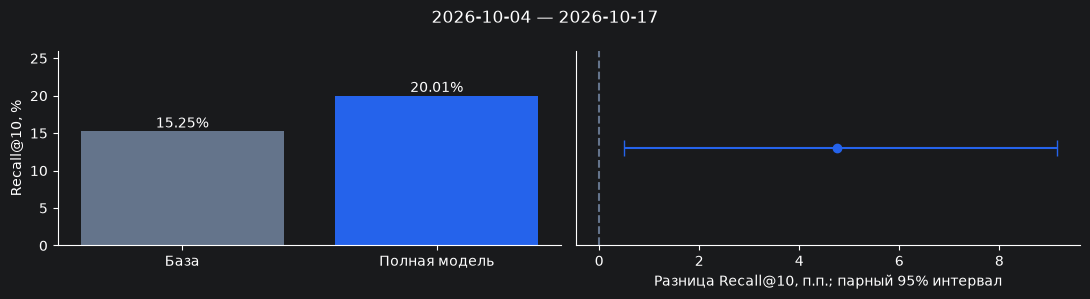

Целей вне пула: 65 — все учтены в знаменателе.


,history,n_skus,n_targets,baseline,system,difference,lower,upper
0,0 кластеров,0,0,—,—,—,—,—
1,1–5 кластеров,14,28,25.0,20.24,-4.76,-21.43,7.14
2,6–20 кластеров,60,112,13.56,20.28,6.72,1.44,13.61
3,21+ кластеров,59,124,14.67,19.68,5.01,-1.27,12.08


Срезы: объём прошлой продающей истории; парный bootstrap по товарам, 2000 повторов.


,missing,blank
field,,
date,0,0
sku,0,0
query,0,0
unique_search_users,0,0
unique_view_users,0,0
order_count,0,0


,zeros_pct,median,p95,p99,max,iqr_fence,above_fence
field,,,,,,,
order_count,95.202,0.0,0.0,1.00,98.0,0.0,158220
unique_view_users,0.349,1.0,17.0,80.00,2930.0,6.0,399424
unique_search_users,0.726,5.0,1021.0,5616.62,42544.0,101.0,581300


Дубликатов ключа: 0
Строк с заказами без просмотров: 11503
Покрытие заказов фиксированным словарём, %: 82.19


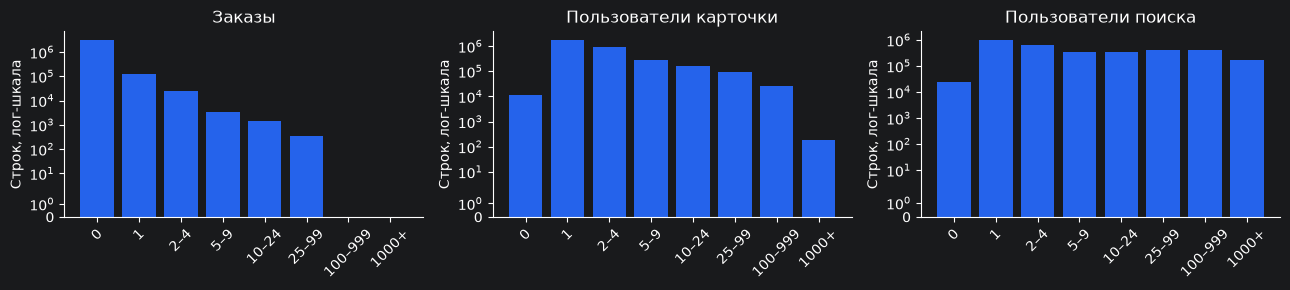

Метрики, срезы, анализ данных и контрольные суммы: reports/notebook_current_validation.json
Пересчёт исследования зафиксирован: данные, код, библиотеки и отчёты связаны контрольными суммами.


In [37]:
from fresh_validation import run_closed_validation
from automatic_check import record_study_cache
import gc

globals().pop('review_study', None)
gc.collect()
current_validation = run_closed_validation(ROOT, current_source)
assert current_validation['target_days'] == 14
assert not current_validation['training_performed']
assert not current_validation['hyperparameter_selection_performed']
print('История:', current_validation['history_start'], '—', current_validation['decision'])
print('Целевое окно:', current_validation['target_start'], '—', current_validation['target_end'])
print('Каталог:', current_validation['catalog_clusters'], '| общий пул:', current_validation['candidate_pairs'])

current_table = pd.DataFrame(current_validation['models']).T
assert current_table.positive_pairs.nunique() == current_table.evaluated_skus.nunique() == 1
current_table['Recall@10, %'] = 100 * current_table['recall@10']
current_table['Precision@10 proxy, %'] = 100 * current_table['precision@10']
display(current_table[['Recall@10, %', 'ndcg@10', 'Precision@10 proxy, %',
                       'positive_pairs', 'evaluated_skus']].sort_values('Recall@10, %', ascending=False).round(4))
current_interval = current_validation['interval']
if current_interval['n_targets']:
    print('Полная модель минус база, п.п.:', round(100 * current_interval['difference'], 2))
    print('Парный 95% интервал, п.п.:',
          [round(100 * current_interval[key], 2) for key in ['lower', 'upper']])
    print('Преимущество в этом окне:',
          'подтверждено' if current_validation['effect_confirmed_on_window'] else 'не подтверждено')
    fig, axes = plt.subplots(1, 2, figsize=(11, 3))
    values = [100 * current_interval[key] for key in ['baseline', 'system']]
    axes[0].bar(['База', 'Полная модель'], values, color=['#64748b', '#2563eb'])
    axes[0].set_ylabel('Recall@10, %'); axes[0].set_ylim(0, max(values) * 1.3)
    for position, value in enumerate(values):
        axes[0].text(position, value + .5, f'{value:.2f}%', ha='center')
    gain = 100 * current_interval['difference']
    axes[1].errorbar(gain, 0, xerr=[[gain - 100 * current_interval['lower']],
        [100 * current_interval['upper'] - gain]], fmt='o', capsize=6, color='#2563eb')
    axes[1].axvline(0, color='#64748b', linestyle='--'); axes[1].set_yticks([])
    axes[1].set_xlabel('Разница Recall@10, п.п.; парный 95% интервал')
    for ax in axes: ax.spines[['top', 'right']].set_visible(False)
    fig.suptitle(current_validation['target_start'] + ' — ' + current_validation['target_end'])
    fig.tight_layout(); plt.show(); plt.close(fig)
else:
    print('В окне нет подходящих продающих пар: качество не определяется.')
print('Целей вне пула:', current_validation['targets_not_retrieved'], '— все учтены в знаменателе.')

current_slices = pd.DataFrame(current_validation['slices'])
for key in ['baseline', 'system', 'difference', 'lower', 'upper']:
    current_slices[key] = 100 * pd.to_numeric(current_slices[key])
display(current_slices[['history', 'n_skus', 'n_targets', 'baseline', 'system',
                        'difference', 'lower', 'upper']].round(2).fillna('—'))
print('Срезы: объём прошлой продающей истории; парный bootstrap по товарам, 2000 повторов.')

current_eda = current_validation['data_overview']
display(pd.DataFrame(current_eda['fields']).set_index('field'))
display(pd.DataFrame(current_eda['distributions']).set_index('field').round(3))
print('Дубликатов ключа:', current_eda['duplicate_keys'])
print('Строк с заказами без просмотров:', current_eda['orders_without_views_rows'])
print('Покрытие заказов фиксированным словарём, %:',
      round(100 * current_validation['normalization']['order_coverage'], 2))
fig, axes = plt.subplots(1, 3, figsize=(13, 3))
bin_labels = ['0', '1', '2–4', '5–9', '10–24', '25–99', '100–999', '1000+']
for ax, field, title in zip(axes, ['order_count', 'unique_view_users', 'unique_search_users'],
                          ['Заказы', 'Пользователи карточки', 'Пользователи поиска']):
    ax.bar(bin_labels, current_eda['histograms'][field], color='#2563eb')
    ax.set_yscale('symlog'); ax.tick_params(axis='x', rotation=45)
    ax.set_title(title); ax.set_ylabel('Строк, лог-шкала')
    ax.spines[['top', 'right']].set_visible(False)
fig.tight_layout(); plt.show(); plt.close(fig)
print('Метрики, срезы, анализ данных и контрольные суммы: reports/notebook_current_validation.json')
if all((ROOT / research_config['inputs'][key]).is_file() for key in ['facts', 'dictionary', 'embeddings']):
    recorded_study = record_study_cache(ROOT)
    print('Пересчёт исследования зафиксирован: данные, код, библиотеки и отчёты связаны контрольными суммами.')

In [38]:
channel_interval = current_validation['channel_count_interval']
if channel_interval['n_targets']:
    print('Полная модель против E5 + совместные продажи + TF-IDF + популярность, п.п.:',
          round(100 * channel_interval['difference'], 2))
    print('Парный 95% интервал, п.п.:',
          [round(100 * channel_interval[key], 2) for key in ['lower', 'upper']])

positive_slice_names = [row['history'] for row in current_validation['slices']
                        if row['n_targets'] and row['lower'] > 0]
negative_slice_names = [row['history'] for row in current_validation['slices']
                        if row['n_targets'] and row['difference'] < 0]
display(Markdown('**Товарные срезы.** Интервал разницы целиком выше нуля для групп: '
    + (', '.join(positive_slice_names) or 'нет таких групп')
    + '. Средний результат ниже базы для групп: '
    + (', '.join(negative_slice_names) or 'нет таких групп')
    + '. Указаны отдельные 95%-е интервалы без поправки на множественные сравнения.'))

Полная модель против E5 + совместные продажи + TF-IDF + популярность, п.п.: 5.12
Парный 95% интервал, п.п.: [0.62, 9.6]


**Товарные срезы.** Интервал разницы целиком выше нуля для групп: 6–20 кластеров. Средний результат ниже базы для групп: 1–5 кластеров. Указаны отдельные 95%-е интервалы без поправки на множественные сравнения.